In [1]:

import os, sys
os.environ['CUDA_VISIBLE_DEVICES'] = "3"
import torch
from tqdm import tqdm
import numpy as np
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
import matplotlib as plt
from PIL import Image
sys.path.append('../src')

from sklearn.preprocessing import MinMaxScaler
from utils import *
from matplotlib.lines import Line2D
import matplotlib as mpl
import math
import matplotlib.image as mpimg
import scipy.stats as stats
import scipy as sp
from sklearn.decomposition import PCA
from scipy.stats import pearsonr,binom,linregress
from ast import literal_eval
import json
from matplotlib.colors import ListedColormap
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1 import make_axes_locatable
from scipy.stats import gaussian_kde
from matplotlib.patches import Ellipse
import seaborn as sns
os.chdir("..")

# Feature Metric Tables

In [2]:
# Assemble dataframes
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/dataframes/"
method = "brain-optimized-inference_2.1"
df = pd.DataFrame()
for subject in [1,2,5,7]:
    new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = -1
    new_df["subject"] = subject
    new_df["method"] = "MindEye1"
    df = pd.concat([df, new_df])
    for iteration in range(6):
        new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
        new_df["iteration"] = iteration
        new_df["subject"] = subject
        new_df["method"] = "MindEye1"
        df = pd.concat([df, new_df])
    new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = 6
    new_df["subject"] = subject
    new_df["method"] = "MindEye1"
    df = pd.concat([df, new_df])

method = "brain-optimized-inference_2.3"
for subject in [1,2,5,7]:
    new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = -1
    new_df["subject"] = subject
    new_df["method"] = "Brain Diffuser"
    df = pd.concat([df, new_df])
    for iteration in range(6):
        new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
        new_df["iteration"] = iteration
        new_df["subject"] = subject
        new_df["method"] = "Brain Diffuser"
        df = pd.concat([df, new_df])
    new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = 6
    new_df["subject"] = subject
    new_df["method"] = "Brain Diffuser"
    df = pd.concat([df, new_df])

method = "brain-optimized-inference_2.4"
for subject in [1,2,5,7]:
    new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = -1
    new_df["subject"] = subject
    new_df["method"] = "MIRAGE"
    df = pd.concat([df, new_df])
    for iteration in range(6):
        new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
        new_df["iteration"] = iteration
        new_df["subject"] = subject
        new_df["method"] = "MIRAGE"
        df = pd.concat([df, new_df])
    new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = 6
    new_df["subject"] = subject
    new_df["method"] = "MIRAGE"
    df = pd.concat([df, new_df])



df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']

In [44]:
from torchvision import transforms
df = df[(df['method'] == "Brain Diffuser") & (df['subject'] == 1)]
print(len(df))
df.head(20)


8000


,Unnamed: 0,sample,repetition,PixCorr,SSIM,AlexNet(1),AlexNet(2),AlexNet(3),AlexNet(4),AlexNet(5),AlexNet(6),AlexNet(7),InceptionV3,CLIP,EffNet-B,SwAV,Brain Corr. nsd_general,Brain Corr. higher_vis,Brain Corr. EVC,iteration,subject,method
0,0,0,0,0.173644,0.147716,0.669670,0.915916,0.984985,0.941942,0.950951,0.974975,0.983984,0.980981,0.954955,0.278081,0.561321,0.218160,0.143887,0.238627,-1,1,Brain Diffuser
1,1,1,0,0.196236,0.178291,0.882883,0.977978,0.989990,0.991992,0.986987,0.995996,0.994995,0.952953,0.995996,0.270406,0.598683,0.216978,0.242143,0.131249,-1,1,Brain Diffuser
2,2,2,0,0.184093,0.474387,0.992993,0.997998,0.998999,0.998999,0.997998,0.973974,0.946947,0.991992,0.939940,0.285052,0.626955,0.397303,0.432316,0.421208,-1,1,Brain Diffuser
3,3,3,0,0.199818,0.383100,0.897898,0.997998,0.998999,0.998999,0.998999,0.993994,0.993994,0.898899,0.892893,0.208956,0.442605,0.356599,0.223433,0.538999,-1,1,Brain Diffuser
4,4,4,0,0.493538,0.355930,0.976977,0.971972,0.969970,0.950951,0.925926,0.837838,0.878879,0.638639,0.221221,-0.005018,0.481928,0.493842,0.566406,0.319760,-1,1,Brain Diffuser
5,5,5,0,0.370069,0.198602,0.978979,0.993994,0.995996,0.996997,0.995996,0.994995,0.991992,0.998999,0.947948,0.412042,0.595770,0.645662,0.623966,0.408287,-1,1,Brain Diffuser
6,6,6,0,0.413735,0.248785,0.972973,0.993994,0.998999,0.998999,0.974975,0.984985,0.975976,0.988989,0.821822,0.139339,0.538759,0.282057,0.229582,0.376263,-1,1,Brain Diffuser
7,7,7,0,0.508939,0.275814,0.952953,0.951952,0.994995,0.997998,0.998999,0.998999,0.996997,0.980981,0.960961,0.406993,0.602057,0.408266,0.607550,-0.100703,-1,1,Brain Diffuser
8,8,8,0,0.327639,0.487506,0.997998,0.998999,0.998999,0.998999,0.994995,0.940941,0.910911,0.615616,0.870871,0.090043,0.460856,0.229706,0.198241,0.319209,-1,1,Brain Diffuser
9,9,9,0,-0.096161,0.294867,0.850851,0.966967,0.994995,0.993994,0.989990,0.942943,0.943944,0.991992,0.926927,0.309472,0.565200,0.248619,0.230317,0.302368,-1,1,Brain Diffuser


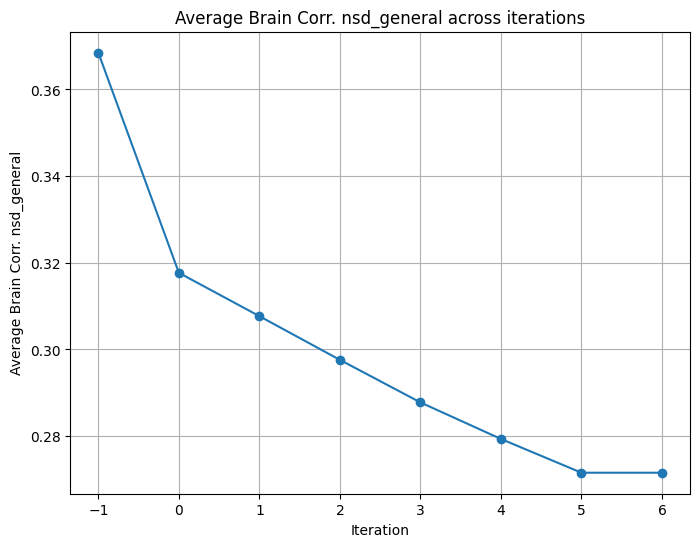

In [45]:
avg_vals = df.groupby("iteration")["Brain Corr. nsd_general"].mean().reset_index()

plt.figure(figsize=(8,6))
plt.plot(avg_vals["iteration"], avg_vals["Brain Corr. nsd_general"], marker="o")
plt.xlabel("Iteration")
plt.ylabel("Average Brain Corr. nsd_general")
plt.title("Average Brain Corr. nsd_general across iterations")
plt.grid(True)
# plt.savefig(os.path.join(output_path, f"{output_file}.png"))
plt.show()

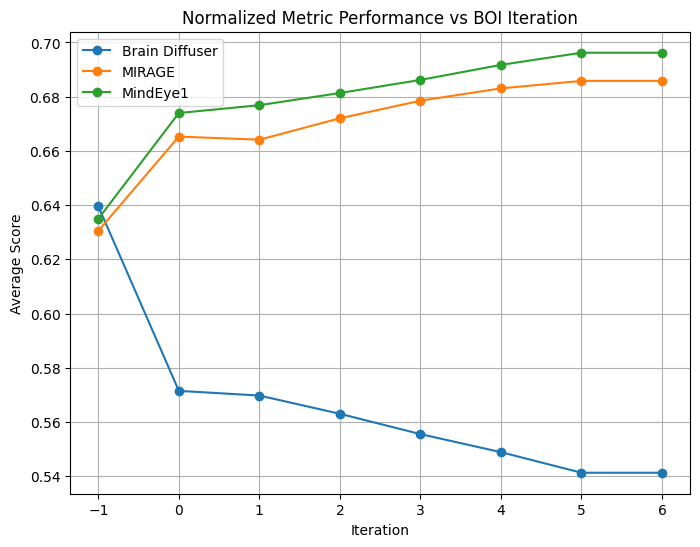

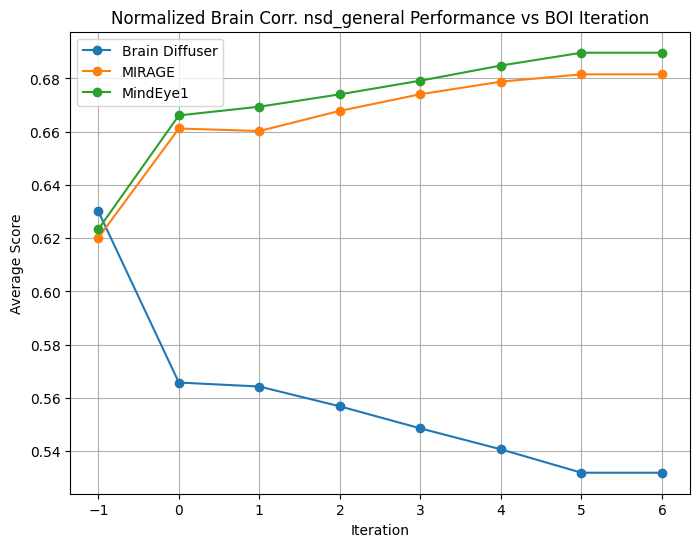

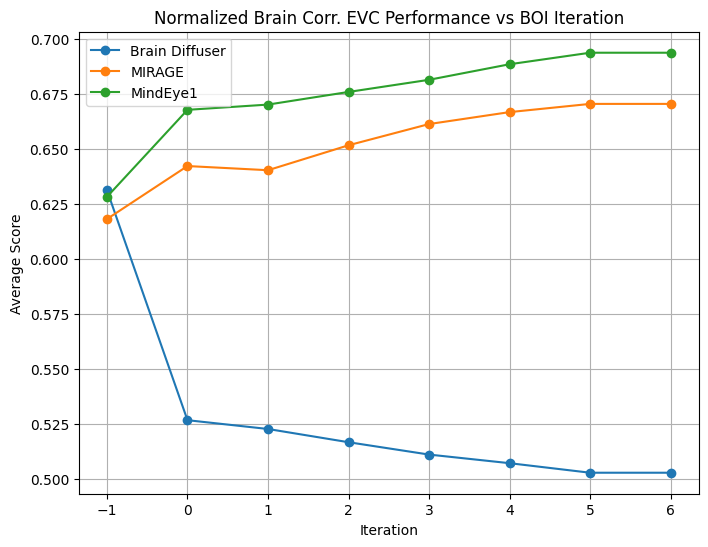

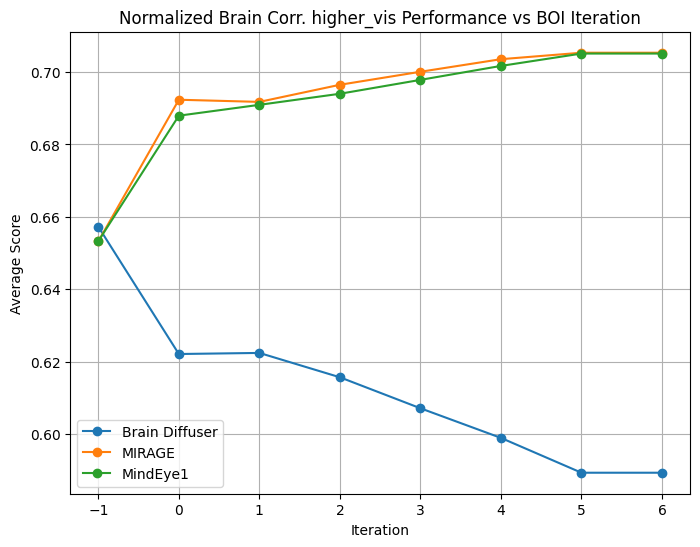

In [3]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/figures/"
criteria = [
    # "PixCorr",
    # "SSIM",
    # "AlexNet(2)",
    # "AlexNet(5)",
    # "InceptionV3",
    # "CLIP",
    # "EffNet-B",
    # "SwAV",
    "Brain Corr. nsd_general",
    "Brain Corr. EVC",
    "Brain Corr. higher_vis",
]

output_file = f"Normalized Metric Performance vs BOI Iteration"
all_metrics = df.copy()
scaler = MinMaxScaler()
all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
method_mode_scores = all_metrics.groupby(['iteration', 'method'])[criteria].mean()
method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
method_mode_scores = method_mode_scores.reset_index()

plt.figure(figsize=(8, 6))
for method in method_mode_scores['method'].unique():
    method_data = method_mode_scores[method_mode_scores['method'] == method]
    plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=method)
plt.xlabel('Iteration')
plt.ylabel('Average Score')
plt.title(output_file)
plt.legend()
plt.grid(True)
# plt.savefig(os.path.join(output_path, f"{output_file}.png"))
plt.show()

for criterion in criteria:
    single_criterion = [criterion]
    output_file = f"Normalized {criterion} Performance vs BOI Iteration"
    all_metrics = df.copy()
    scaler = MinMaxScaler()
    all_metrics[single_criterion] = scaler.fit_transform(all_metrics[single_criterion])
    method_mode_scores = all_metrics.groupby(['iteration', 'method'])[single_criterion].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    method_mode_scores = method_mode_scores.reset_index()
    
    plt.figure(figsize=(8, 6))
    for method in method_mode_scores['method'].unique():
        method_data = method_mode_scores[method_mode_scores['method'] == method]
        plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=method)
    plt.xlabel('Iteration')
    plt.ylabel('Average Score')
    plt.title(output_file)
    plt.legend()
    plt.grid(True)
    # plt.savefig(os.path.join(output_path, f"{output_file}.png"))
    plt.show()


# Retrieval Analysis

In [2]:
# Assemble dataframes
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/dataframes/"
# method = "brain-optimized-inference_2.1"
df = pd.DataFrame()
for metric in ['clip', 'brain_corr']:
    for method in ["braindiffuser", "mindeye1", "mirage"]:
        for subject in [1,2,5,7]:
            for topn in range(1, 64):
                new_df = pd.read_csv(f"{root}/{method}_top{topn}_{metric}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
                new_df["topn"] = topn
                new_df["subject"] = subject
                new_df["method"] = method
                new_df["metric"] = metric
                df = pd.concat([df, new_df])

df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']

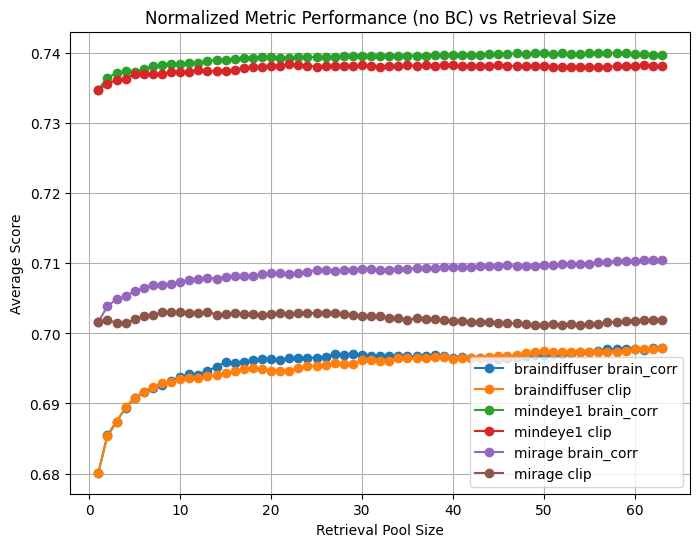

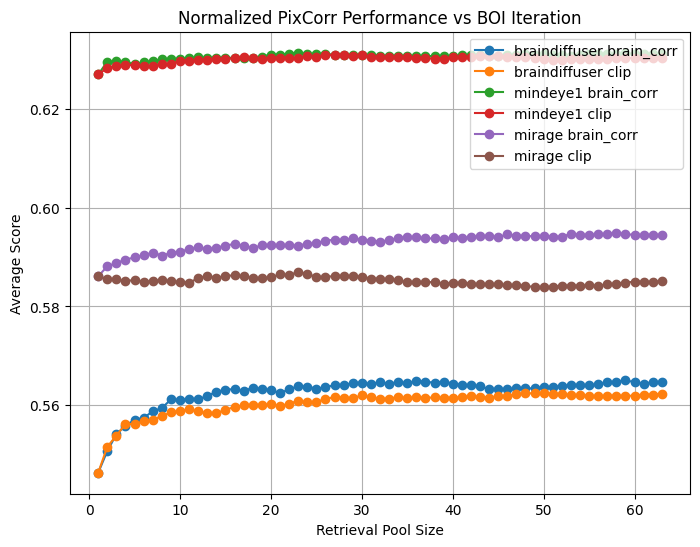

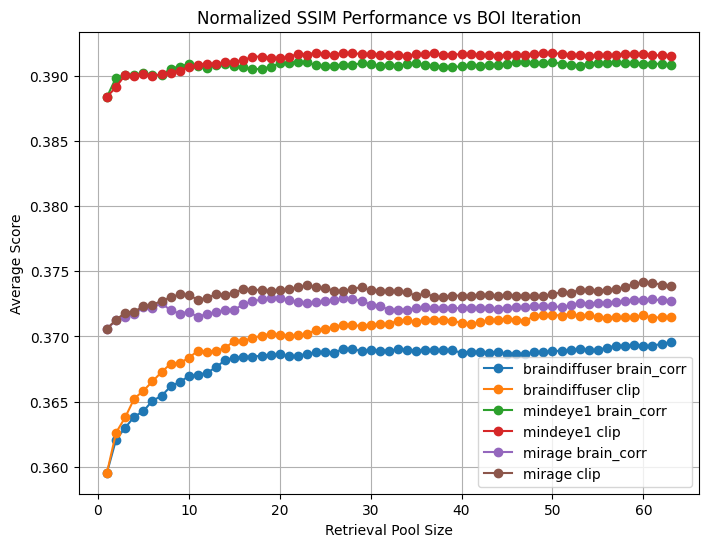

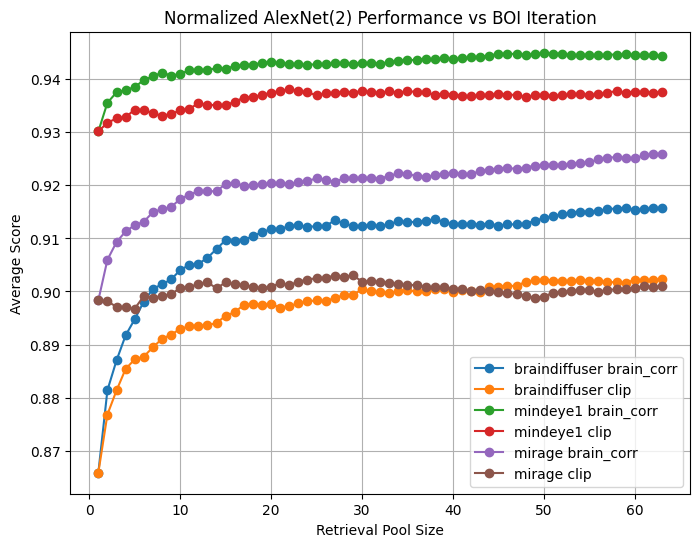

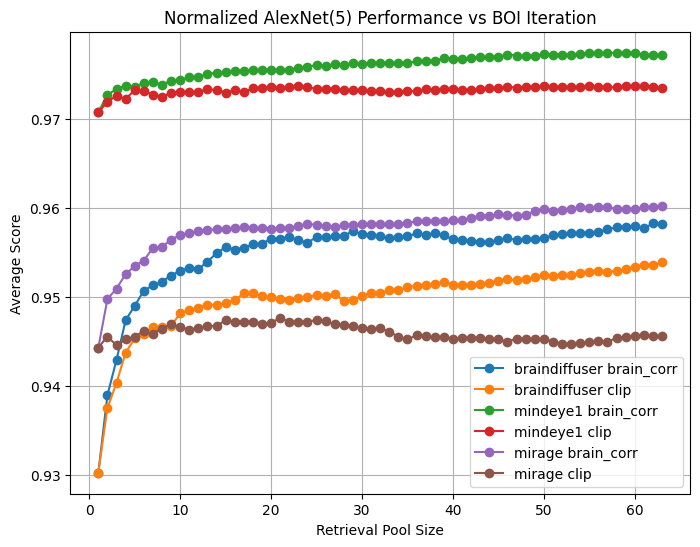

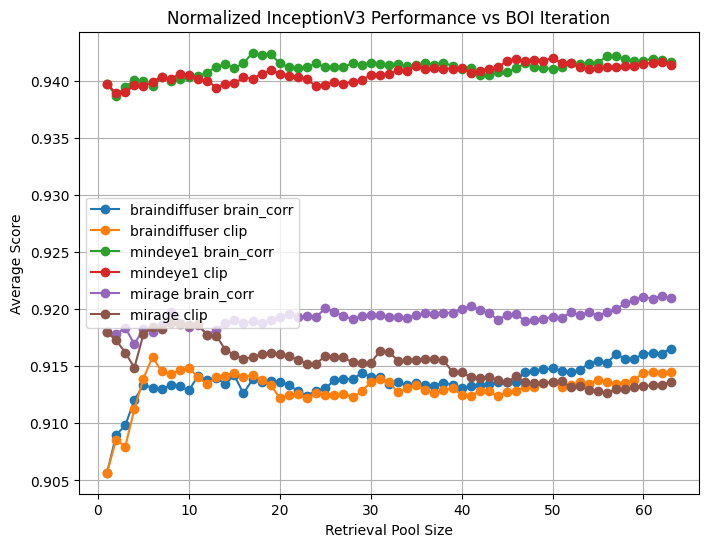

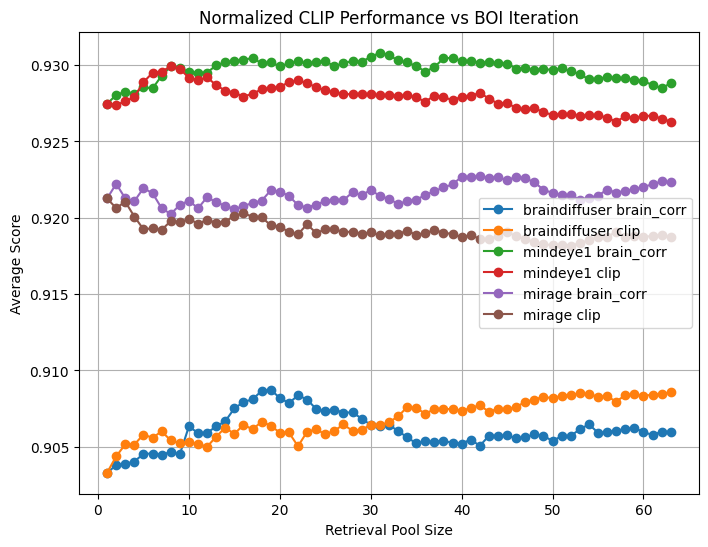

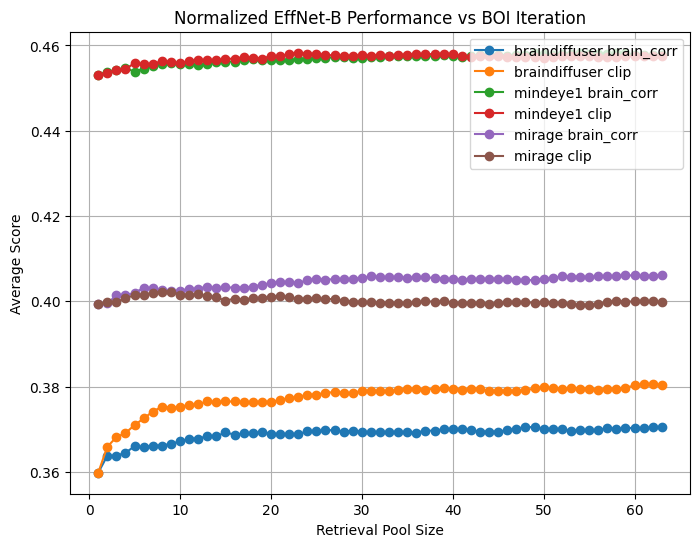

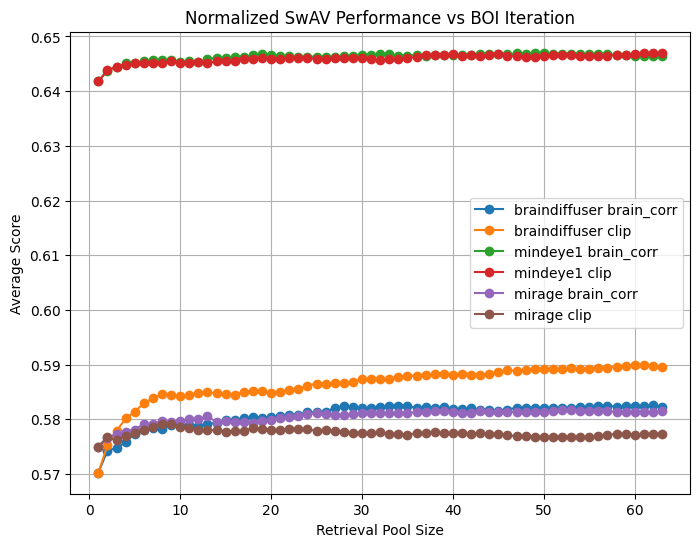

In [ ]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/figures/"
criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    # "Brain Corr. nsd_general",
    # "Brain Corr. EVC",
    # "Brain Corr. higher_vis",
]

output_file = f"Normalized Metric Performance (no BC) vs Retrieval Size"
all_metrics = df.copy()
scaler = MinMaxScaler()
all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
method_mode_scores = all_metrics.groupby(['topn', 'method', 'metric'])[criteria].mean()
method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
method_mode_scores = method_mode_scores.reset_index()

plt.figure(figsize=(8, 6))
for method in method_mode_scores['method'].unique():
    for metric in method_mode_scores['metric'].unique():
        method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
        plt.plot(method_data['topn'], method_data['average_score'], marker='o', label=f"{method} {metric}")
plt.xlabel('Retrieval Pool Size')
plt.ylabel('Average Score')
plt.title(output_file)
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_path, f"{output_file}.png"))
plt.show()

for criterion in criteria:
    single_criterion = [criterion]
    output_file = f"Normalized {criterion} Performance vs BOI Iteration"
    all_metrics = df.copy()
    scaler = MinMaxScaler()
    all_metrics[single_criterion] = scaler.fit_transform(all_metrics[single_criterion])
    method_mode_scores = all_metrics.groupby(['topn', 'method', 'metric'])[single_criterion].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    method_mode_scores = method_mode_scores.reset_index()
    
    plt.figure(figsize=(8, 6))
    for method in method_mode_scores['method'].unique():
        for metric in method_mode_scores['metric'].unique():
            method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
            plt.plot(method_data['topn'], method_data['average_score'], marker='o', label=f"{method} {metric}")
    plt.xlabel('Retrieval Pool Size')
    plt.ylabel('Average Score')
    plt.title(output_file)
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(output_path, f"{output_file}.png"))
    plt.show()


In [4]:
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/dataframes/"
method = "brain-optimized-inference_2.1"
df = pd.DataFrame()
for subject in [1,2,5,7]:
    new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = "base"
    new_df["subject"] = subject
    new_df["method"] = "mindeye1"
    new_df["metric"] = 'brain_corr'
    df = pd.concat([df, new_df])
    for iteration in range(6):
        new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
        new_df["iteration"] = f"iter{iteration}"
        new_df["subject"] = subject
        new_df["method"] = "mindeye1"
        new_df["metric"] = 'brain_corr'
        df = pd.concat([df, new_df])
    new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = f"iter6"
    new_df["subject"] = subject
    new_df["method"] = "mindeye1"
    new_df["metric"] = 'brain_corr'
    df = pd.concat([df, new_df])

method = "brain-optimized-inference_2.3"
for subject in [1,2,5,7]:
    new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = "base"
    new_df["subject"] = subject
    new_df["method"] = "braindiffuser"
    new_df["metric"] = 'brain_corr'
    df = pd.concat([df, new_df])
    for iteration in range(6):
        new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
        new_df["iteration"] = f"iter{iteration}"
        new_df["subject"] = subject
        new_df["method"] = "braindiffuser"
        new_df["metric"] = 'brain_corr'
        df = pd.concat([df, new_df])
    new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = f"iter6"
    new_df["subject"] = subject
    new_df["method"] = "braindiffuser"
    new_df["metric"] = 'brain_corr'
    df = pd.concat([df, new_df])

method = "brain-optimized-inference_2.4"
for subject in [1,2,5,7]:
    new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = "base"
    new_df["subject"] = subject
    new_df["method"] = "mirage"
    new_df["metric"] = 'brain_corr'
    df = pd.concat([df, new_df])
    for iteration in range(6):
        new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
        new_df["iteration"] = f"iter{iteration}"
        new_df["subject"] = subject
        new_df["method"] = "mirage"
        new_df["metric"] = 'brain_corr'
        df = pd.concat([df, new_df])
    new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
    new_df["iteration"] = f"iter6"
    new_df["subject"] = subject
    new_df["method"] = "mirage"
    new_df["metric"] = 'brain_corr'
    df = pd.concat([df, new_df])

for metric in ['clip', 'brain_corr']:
    for method in ["braindiffuser", "mindeye1", "mirage"]:
        for subject in [1,2,5,7]:
            for topn in [1, 8, 16, 32, 63]:
                new_df = pd.read_csv(f"{root}/{method}_top{topn}_{metric}_subj0{subject}_all_recons_shared1000.csv", delimiter="\t")
                new_df["iteration"] = f"top{topn}"
                new_df["subject"] = subject
                new_df["method"] = method
                new_df["metric"] = metric
                df = pd.concat([df, new_df])
iterations = ['base', 'top1', 'top8', 'top16', 'top32', 'top63', 'iter0', 'iter1', 'iter2', 'iter3', 'iter4', 'iter5', 'iter6']

df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']

In [19]:
print(len(df))
print(df['iteration'].unique())

128000
['base' 'iter0' 'iter1' 'iter2' 'iter3' 'iter4' 'iter5' 'iter6' 'top1'
 'top8' 'top16' 'top32']


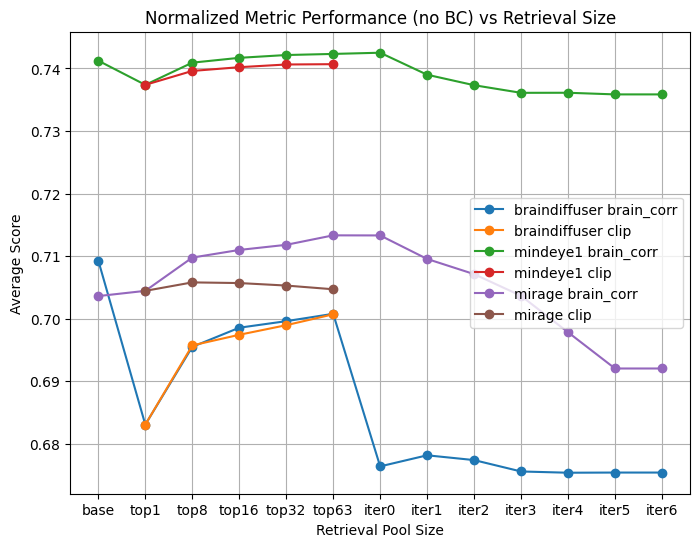

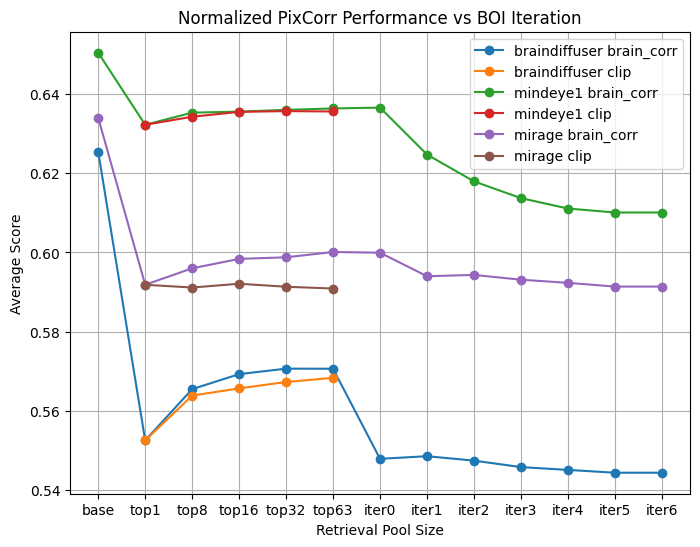

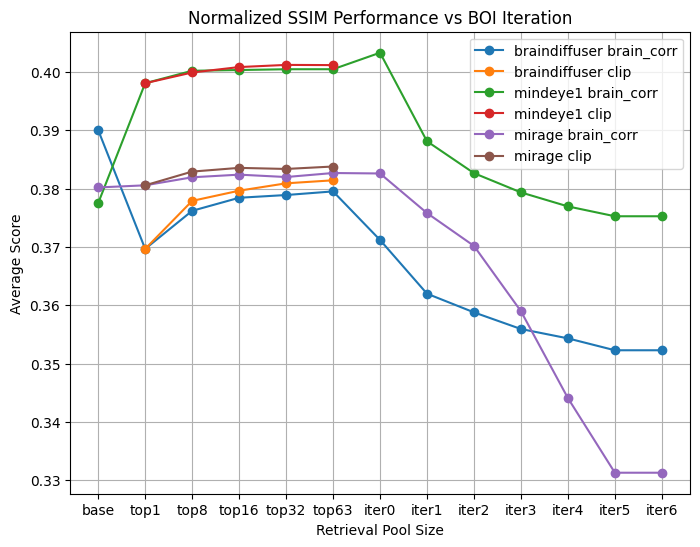

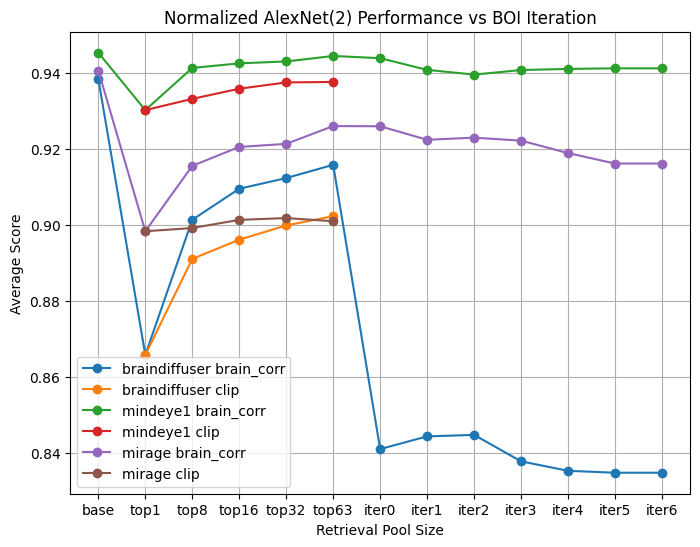

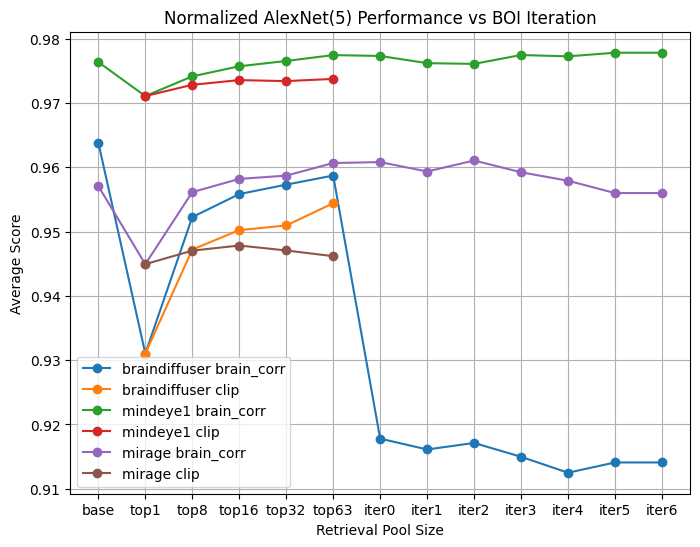

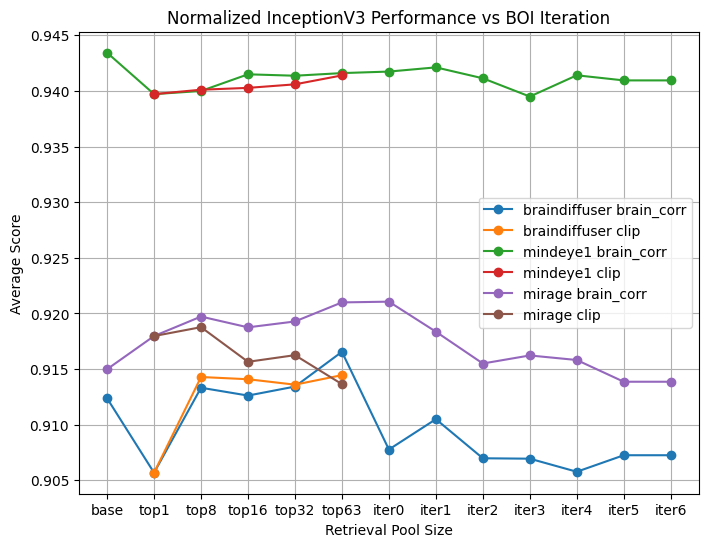

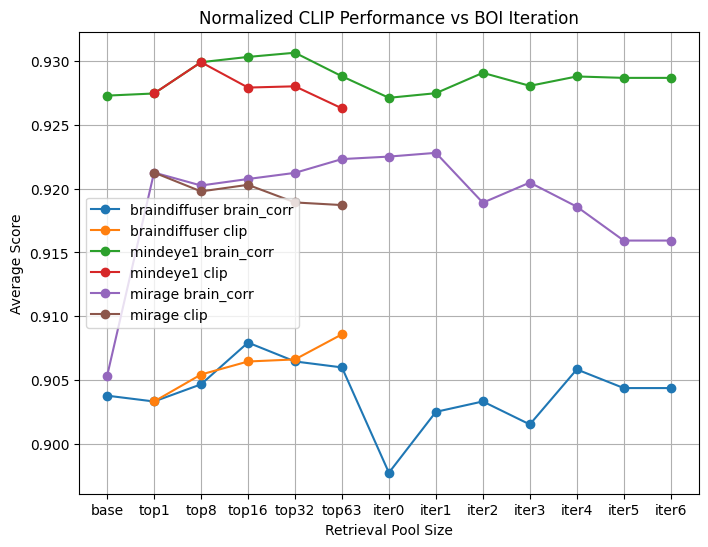

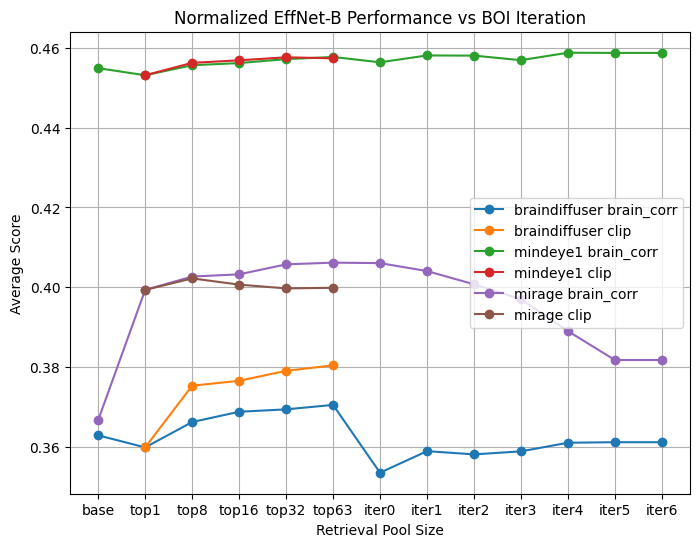

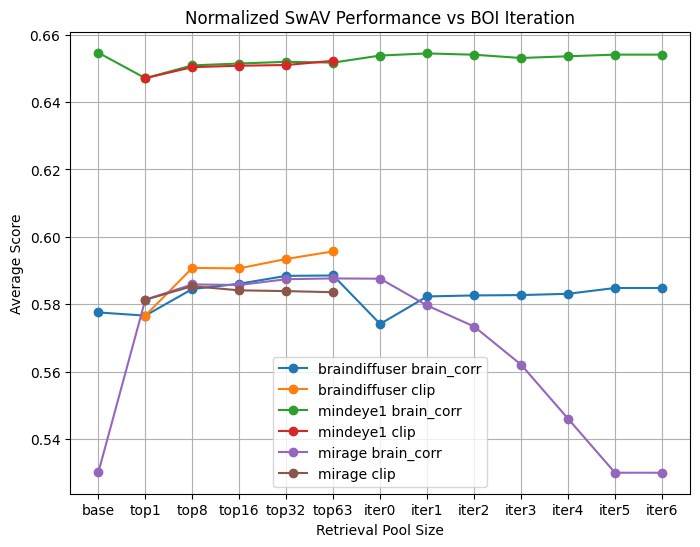

In [5]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/figures/"
criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    # "Brain Corr. nsd_general",
    # "Brain Corr. EVC",
    # "Brain Corr. higher_vis",
]

output_file = f"Normalized Metric Performance (no BC) vs Retrieval Size"
all_metrics = df.copy()
scaler = MinMaxScaler()
all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
all_metrics['iteration'] = pd.Categorical(all_metrics['iteration'], categories=iterations, ordered=True)
method_mode_scores = all_metrics.groupby(['iteration', 'method', 'metric'])[criteria].mean()
method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
method_mode_scores = method_mode_scores.reset_index()

plt.figure(figsize=(8, 6))
for method in method_mode_scores['method'].unique():
    for metric in method_mode_scores['metric'].unique():
        method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
        plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=f"{method} {metric}")
plt.xlabel('Retrieval Pool Size')
plt.ylabel('Average Score')
plt.title(output_file)
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_path, f"{output_file}.png"))
plt.show()

for criterion in criteria:
    single_criterion = [criterion]
    output_file = f"Normalized {criterion} Performance vs BOI Iteration"
    all_metrics = df.copy()
    scaler = MinMaxScaler()
    all_metrics[single_criterion] = scaler.fit_transform(all_metrics[single_criterion])
    all_metrics['iteration'] = pd.Categorical(all_metrics['iteration'], categories=iterations, ordered=True)
    method_mode_scores = all_metrics.groupby(['iteration', 'method', 'metric'])[single_criterion].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    method_mode_scores = method_mode_scores.reset_index()
    
    plt.figure(figsize=(8, 6))
    for method in method_mode_scores['method'].unique():
        for metric in method_mode_scores['metric'].unique():
            method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
            plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=f"{method} {metric}")
    plt.xlabel('Retrieval Pool Size')
    plt.ylabel('Average Score')
    plt.title(output_file)
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(output_path, f"{output_file}.png"))
    plt.show()


# NSD-Imagery results

In [3]:
# Assemble dataframes
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/dataframes/"
df = pd.DataFrame()
for method, name in [("brain-optimized-inference_2.1", "MindEye1"), ("brain-optimized-inference_2.3", "Brain Diffuser"), ("brain-optimized-inference_2.4", "MIRAGE")]:
    for mode in ['imagery', 'vision']:
        for subject in [1,2,5,7]:
            new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
            new_df["iteration"] = -1
            new_df["subject"] = subject
            new_df["method"] = name
            new_df["mode"] = mode
            df = pd.concat([df, new_df])
            for iteration in range(6):
                new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
                new_df["iteration"] = iteration
                new_df["subject"] = subject
                new_df["method"] = name
                new_df["mode"] = mode
                df = pd.concat([df, new_df])
            new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
            new_df["iteration"] = 6
            new_df["subject"] = subject
            new_df["method"] = name
            new_df["mode"] = mode
            df = pd.concat([df, new_df])

df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']

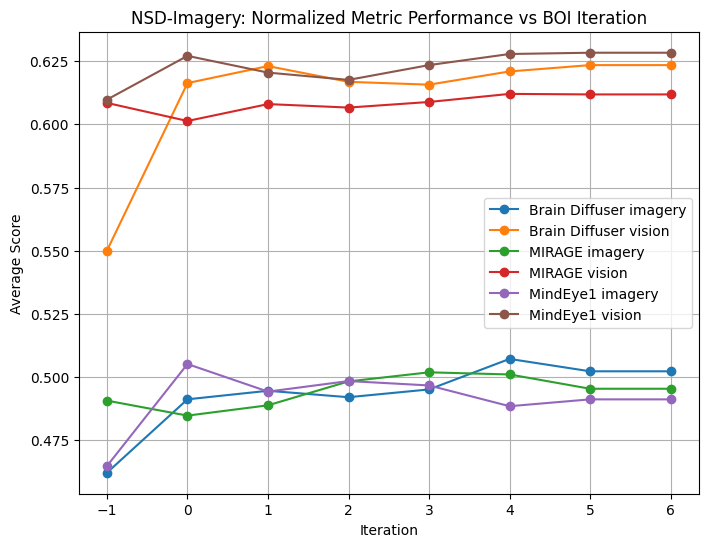

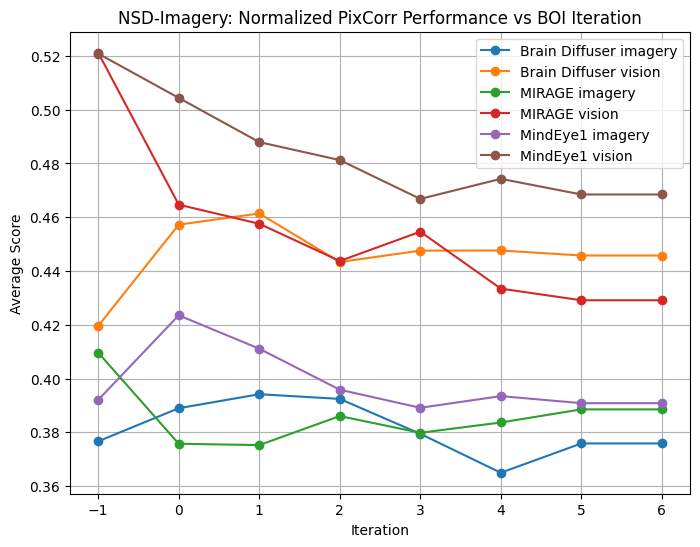

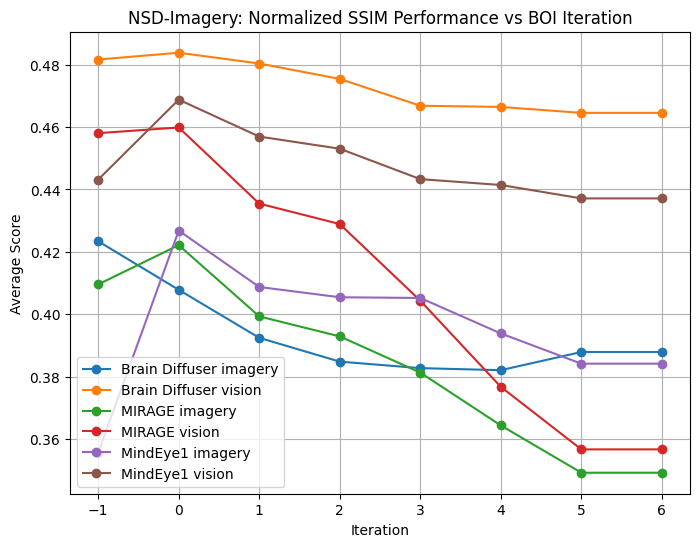

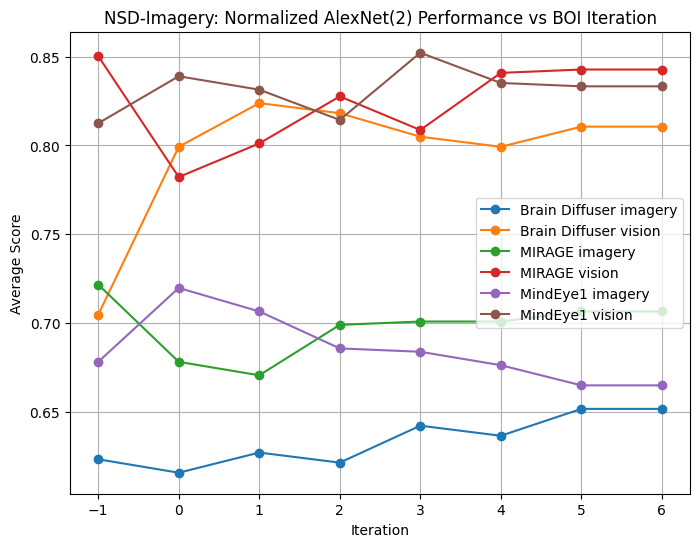

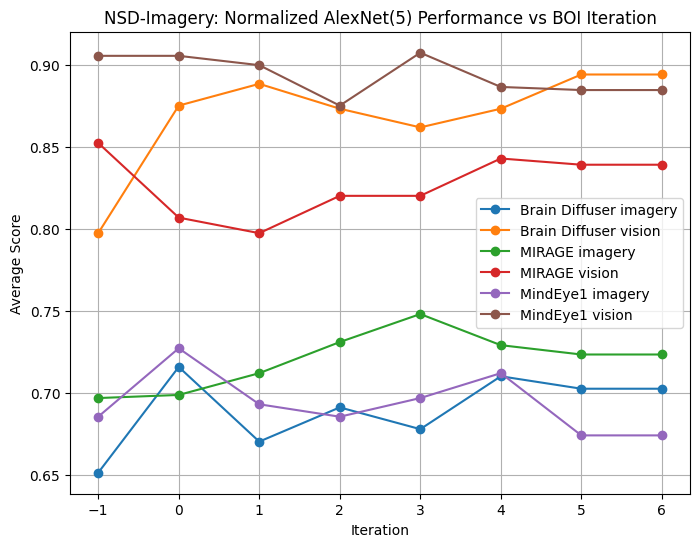

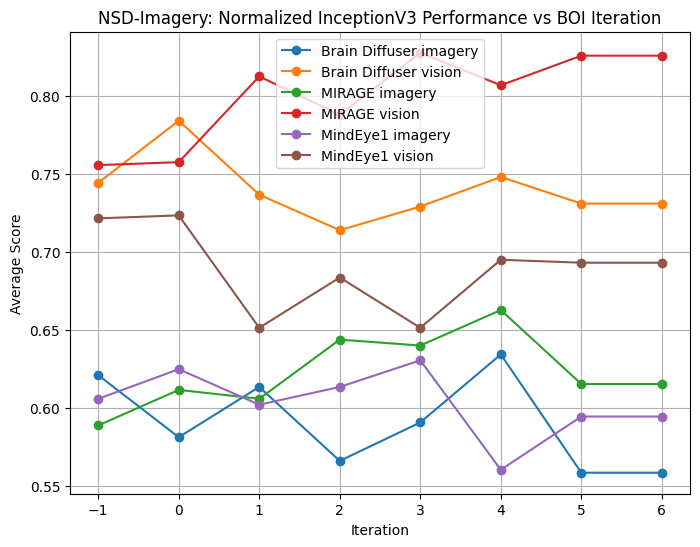

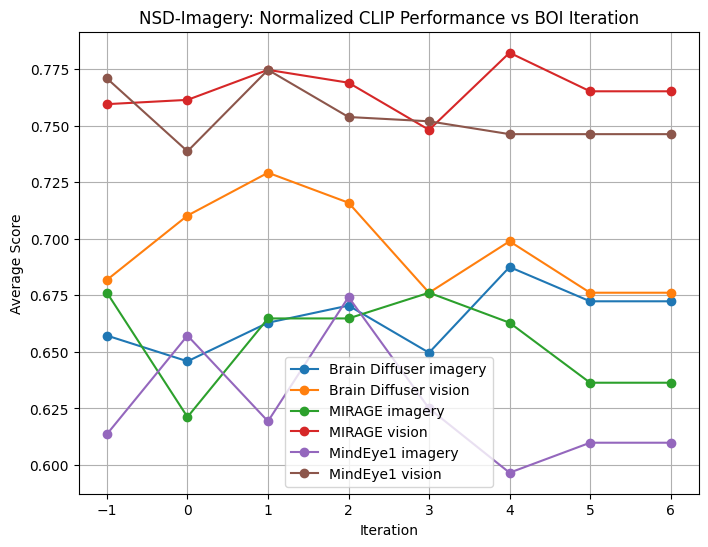

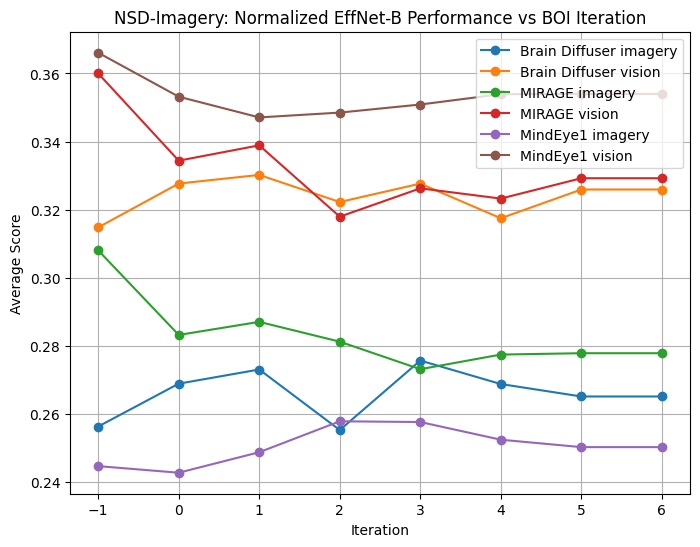

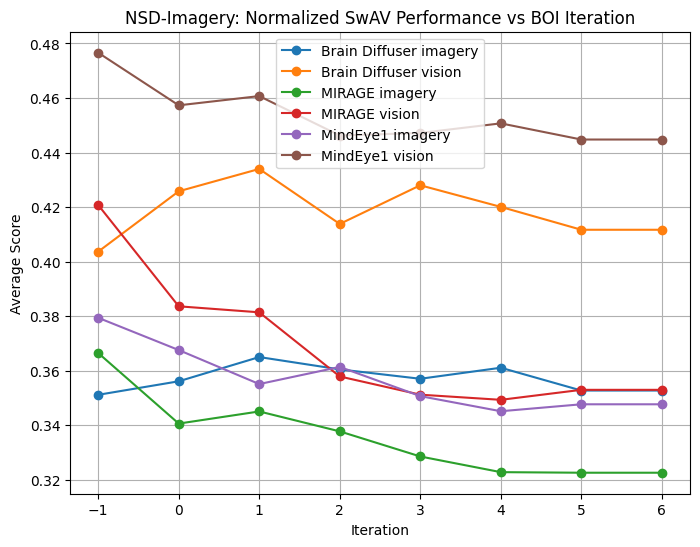

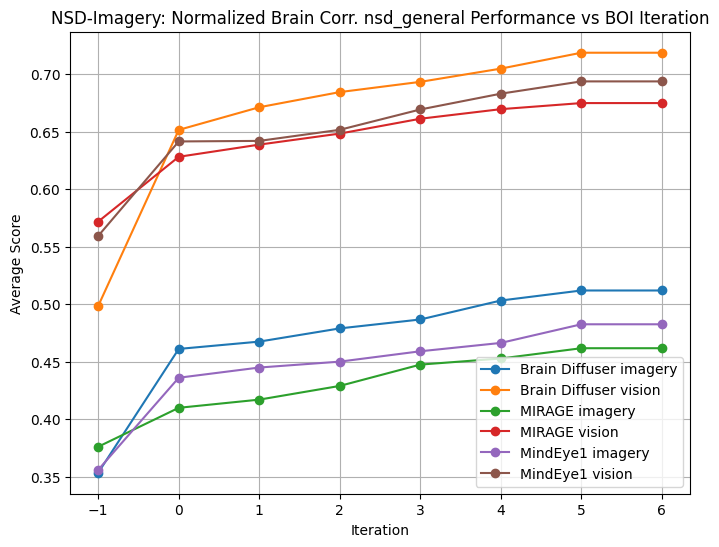

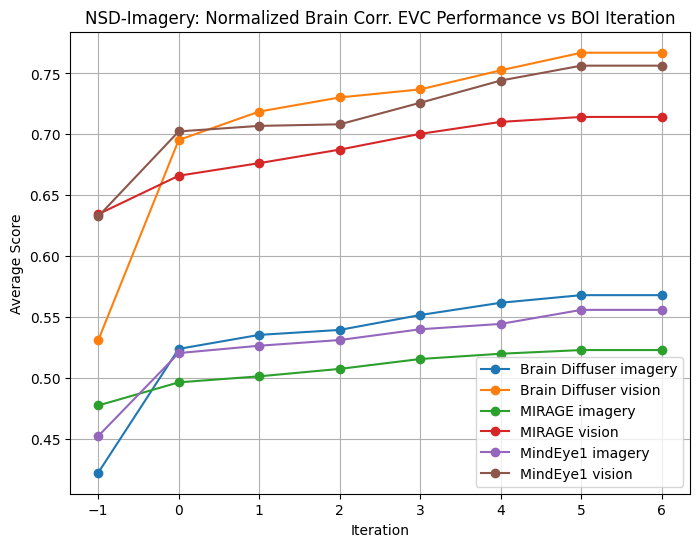

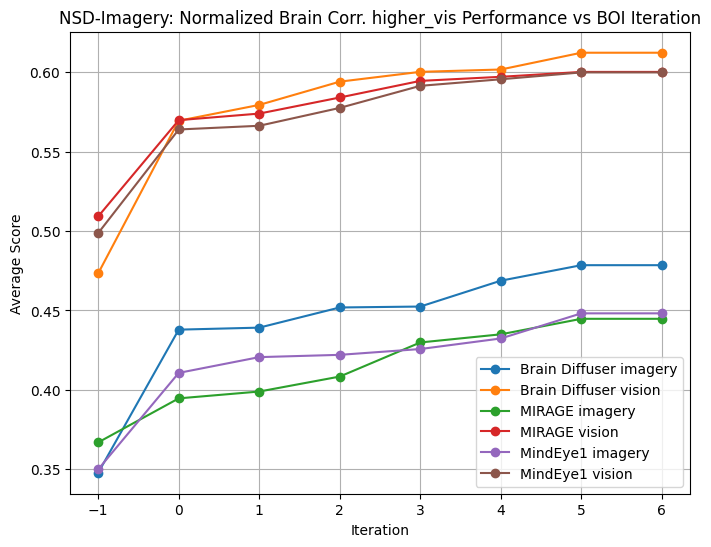

In [6]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/figures/"
criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    "Brain Corr. nsd_general",
    "Brain Corr. EVC",
    "Brain Corr. higher_vis",
]

output_file = f"NSD-Imagery: Normalized Metric Performance vs BOI Iteration"
all_metrics = df.copy()
scaler = MinMaxScaler()
all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
method_mode_scores = all_metrics.groupby(['iteration', 'method', 'mode'])[criteria].mean()
method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
method_mode_scores = method_mode_scores.reset_index()

plt.figure(figsize=(8, 6))
for method in method_mode_scores['method'].unique():
    for mode in method_mode_scores['mode'].unique():
        method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['mode'] == mode)]
        plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=f"{method} {mode}")
plt.xlabel('Iteration')
plt.ylabel('Average Score')
plt.title(output_file)
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_path, f"{output_file}.png"))
plt.show()

for criterion in criteria:
    single_criterion = [criterion]
    output_file = f"NSD-Imagery: Normalized {criterion} Performance vs BOI Iteration"
    all_metrics = df.copy()
    scaler = MinMaxScaler()
    all_metrics[single_criterion] = scaler.fit_transform(all_metrics[single_criterion])
    method_mode_scores = all_metrics.groupby(['iteration', 'method', 'mode'])[single_criterion].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    method_mode_scores = method_mode_scores.reset_index()
    
    plt.figure(figsize=(8, 6))
    for method in method_mode_scores['method'].unique():
        for mode in method_mode_scores['mode'].unique():
            method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['mode'] == mode)]
            plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=f"{method} {mode}")
    plt.xlabel('Iteration')
    plt.ylabel('Average Score')
    plt.title(output_file)
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(output_path, f"{output_file}.png"))
    plt.show()


In [41]:
# Assemble dataframes
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/dataframes/"
df = pd.DataFrame()
for mode in ['imagery', 'vision']:
    for method, name in [("brain-optimized-inference_2.1", "MindEye1"), ("brain-optimized-inference_2.3", "Brain Diffuser"), ("brain-optimized-inference_2.4", "MIRAGE")]:
    
        for subject in [1,2,5,7]:
            new_df = pd.read_csv(f"{root}/{method}_basemodel_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
            new_df["iteration"] = "base"
            new_df["subject"] = subject
            new_df["method"] = name
            new_df["mode"] = mode
            new_df["metric"] = "brain_corr"
            df = pd.concat([df, new_df])
            for iteration in range(6):
                new_df = pd.read_csv(f"{root}/{method}_iter{iteration}_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
                new_df["iteration"] = f"iter{iteration}"
                new_df["subject"] = subject
                new_df["method"] = name
                new_df["mode"] = mode
                new_df["metric"] = "brain_corr"
                df = pd.concat([df, new_df])
            new_df = pd.read_csv(f"{root}/{method}_searchrecon_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
            new_df["iteration"] = f"iter6"
            new_df["subject"] = subject
            new_df["method"] = name
            new_df["mode"] = mode
            new_df["metric"] = "brain_corr"
            df = pd.concat([df, new_df])
    for method, name in [("mindeye1", "MindEye1"), ("braindiffuser", "Brain Diffuser"), ("mirage", "MIRAGE")]:
        for metric in ['clip', 'brain_corr']:
            for subject in [1,2,5,7]:
                for topn in [1, 8, 16, 32, 63]:
                    new_df = pd.read_csv(f"{root}/{method}_top{topn}_{metric}_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
                    new_df["iteration"] = f"top{topn}"
                    new_df["subject"] = subject
                    new_df["method"] = name
                    new_df["metric"] = metric
                    new_df["mode"] = mode
                    df = pd.concat([df, new_df])
iterations = ['base', 'top1', 'top8', 'top16', 'top32', 'top63', 'iter0', 'iter1', 'iter2', 'iter3', 'iter4', 'iter5', 'iter6']

df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']
print(len(df))
df.dropna(inplace=True)
print(len(df))

5184
5184


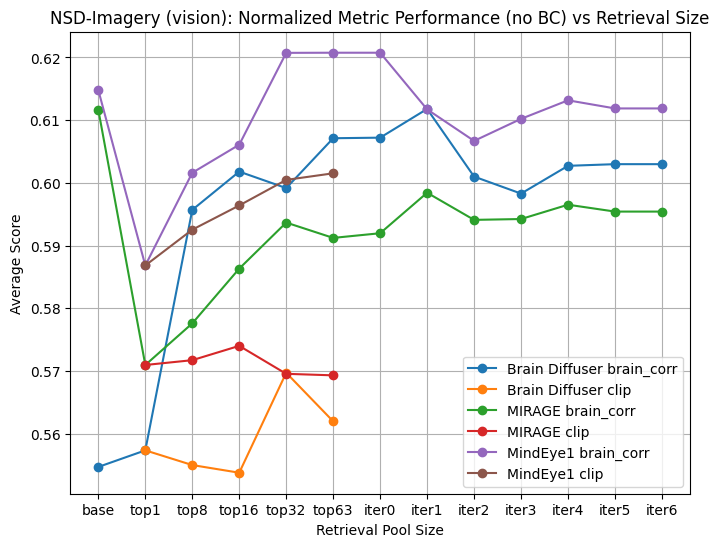

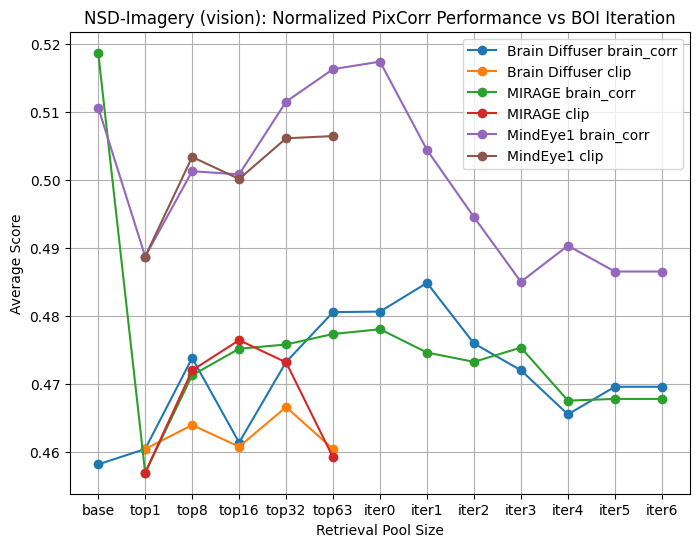

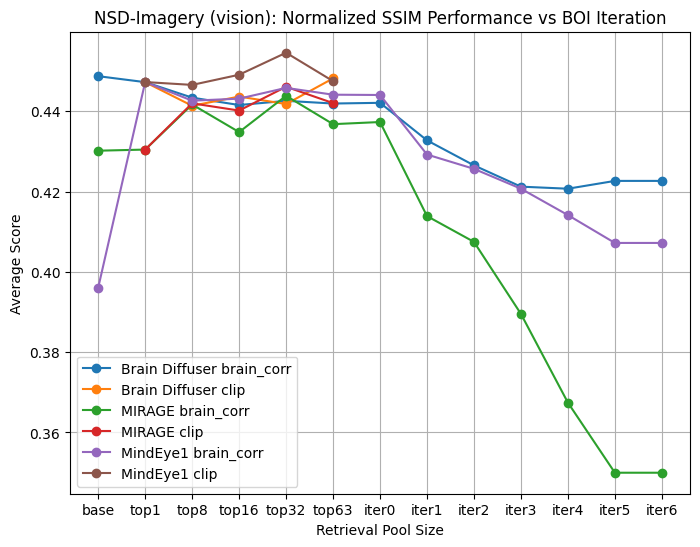

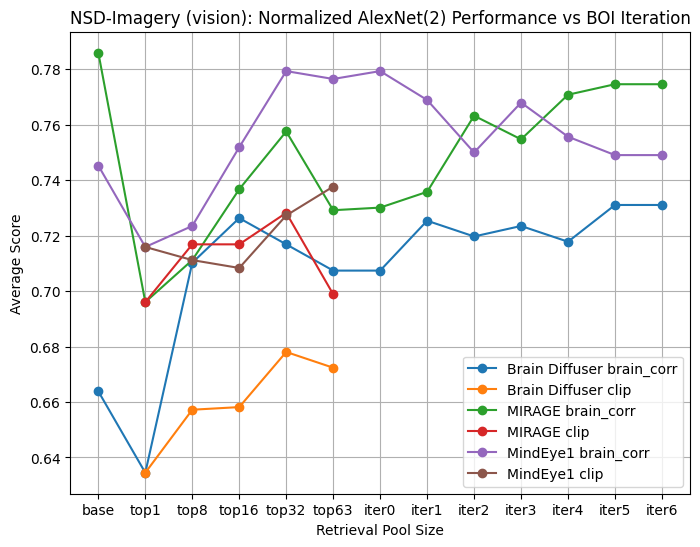

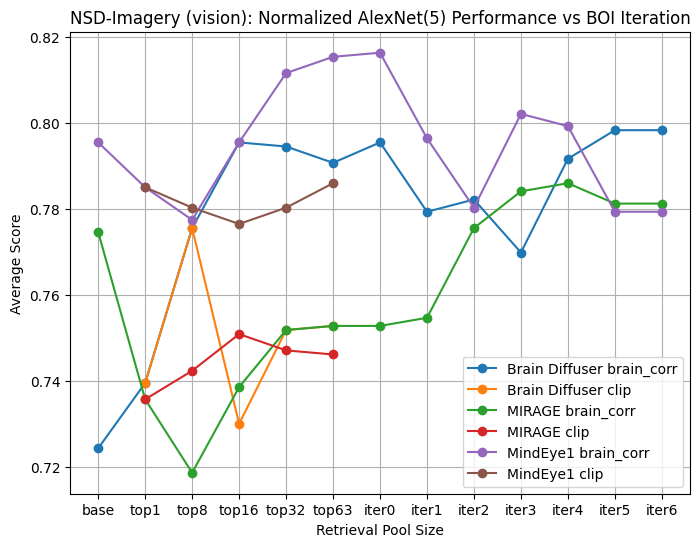

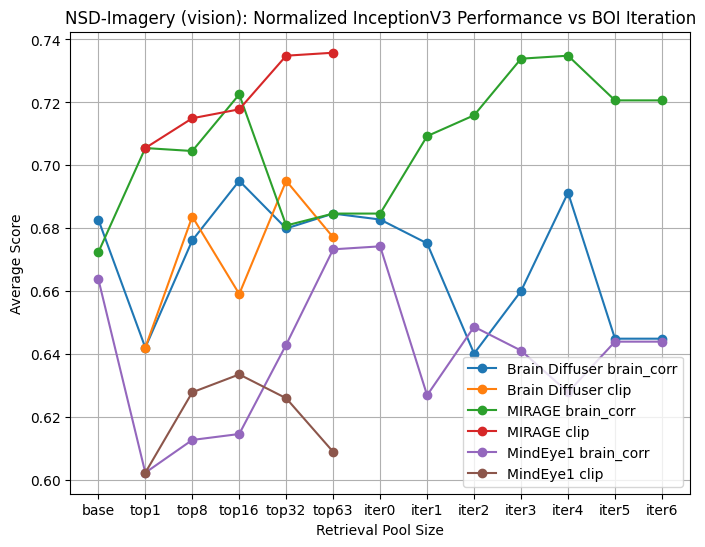

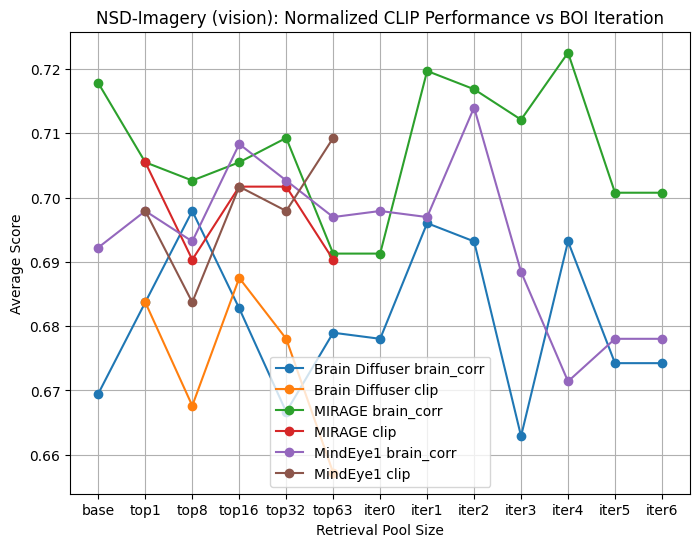

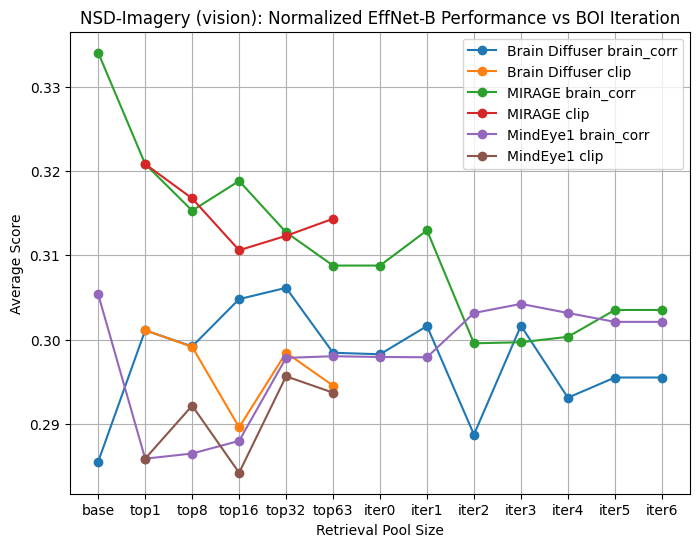

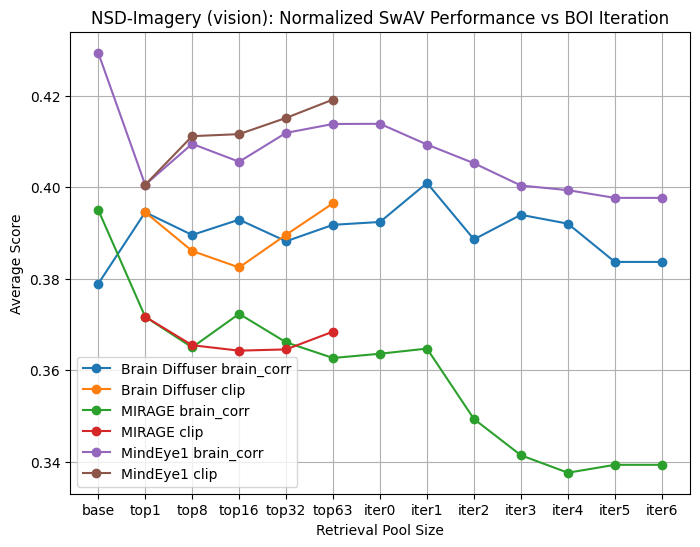

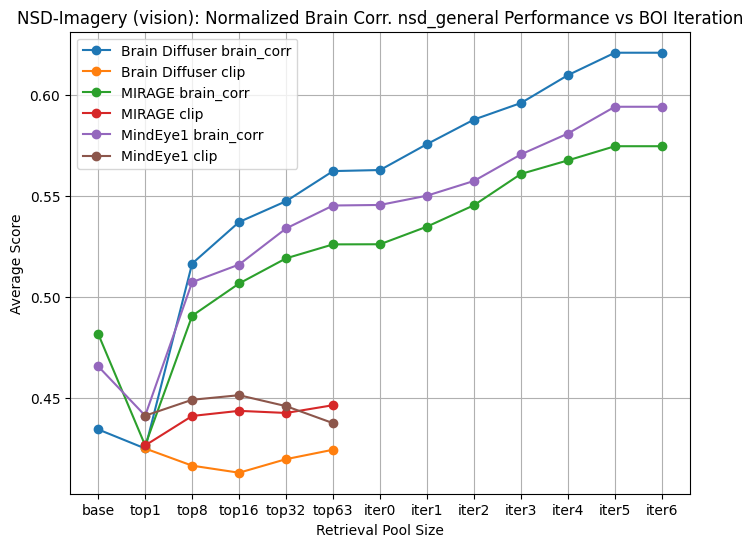

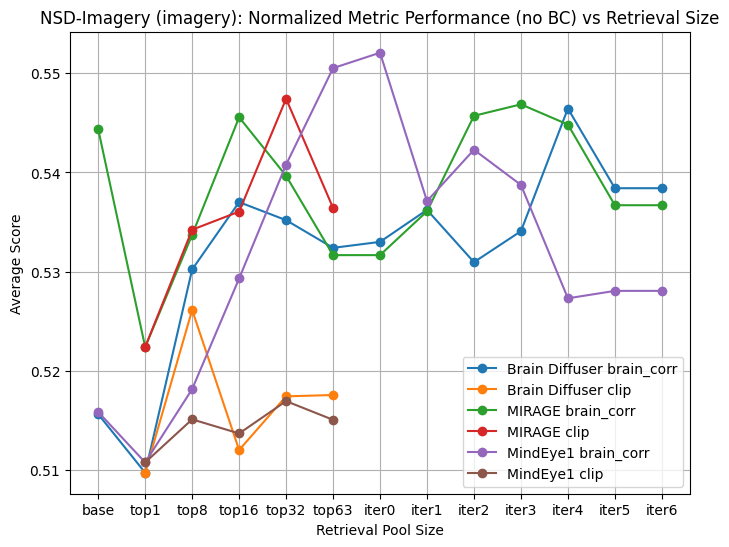

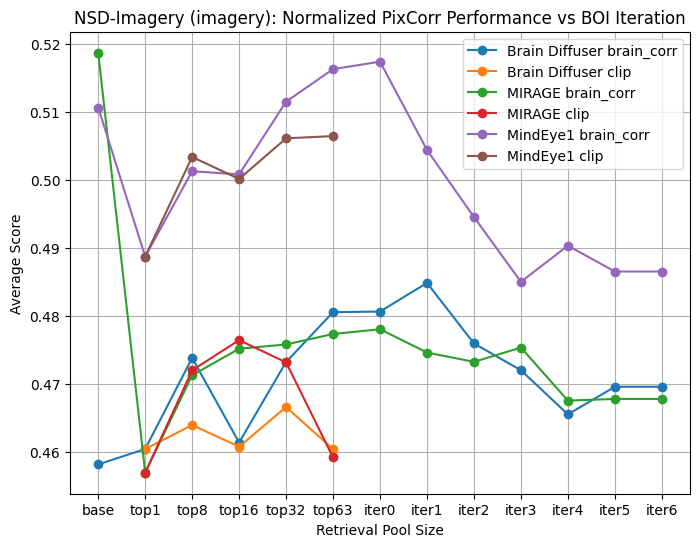

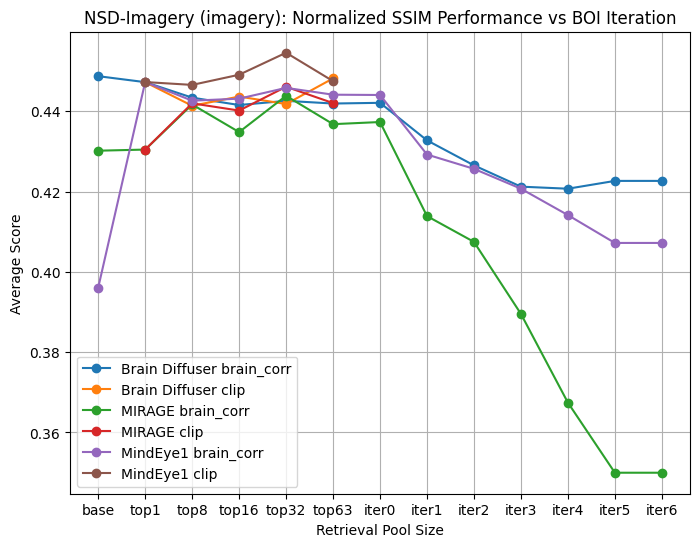

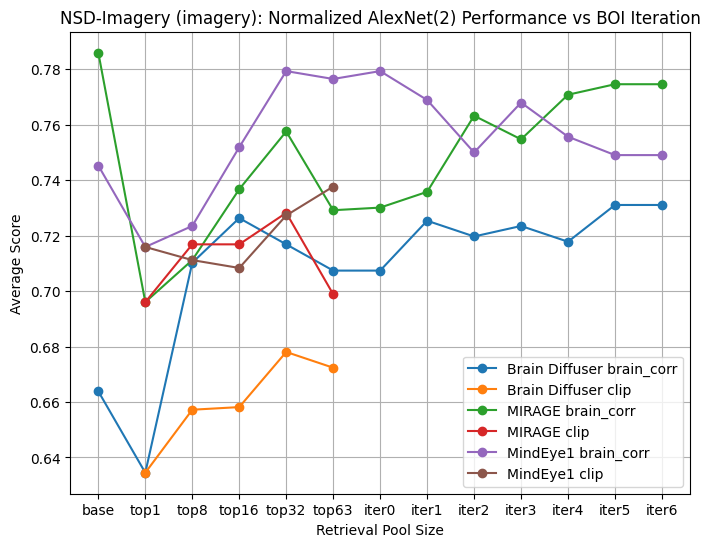

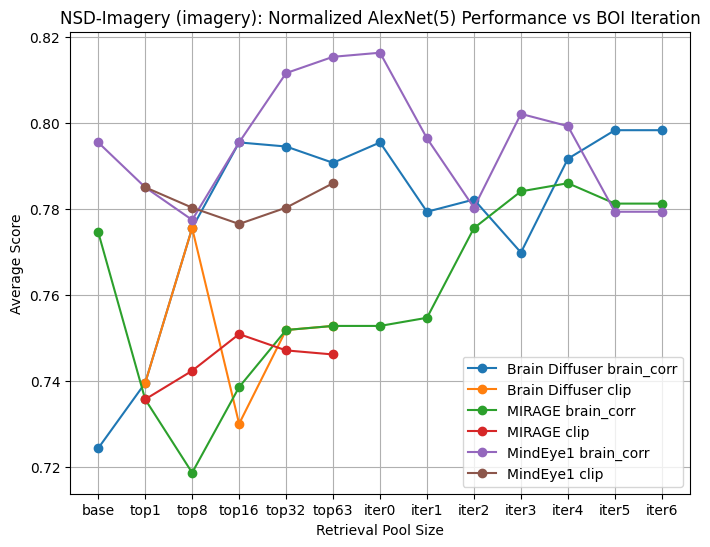

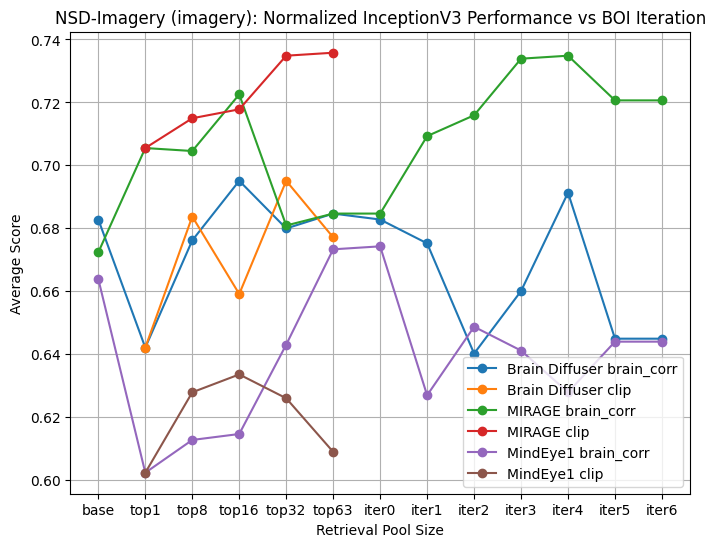

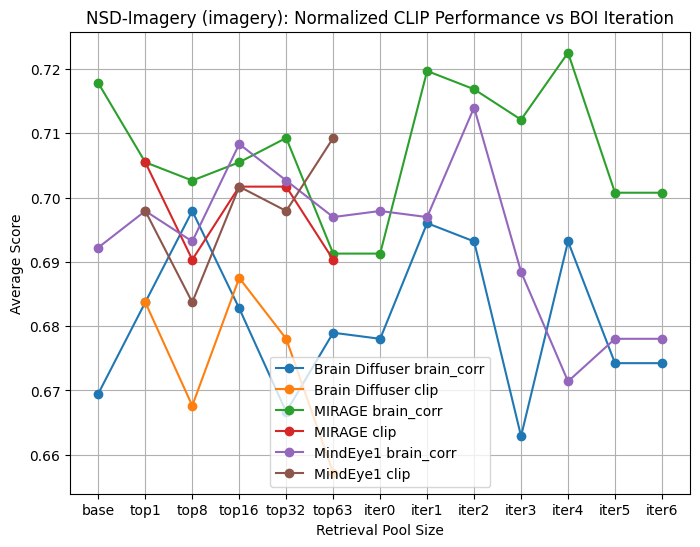

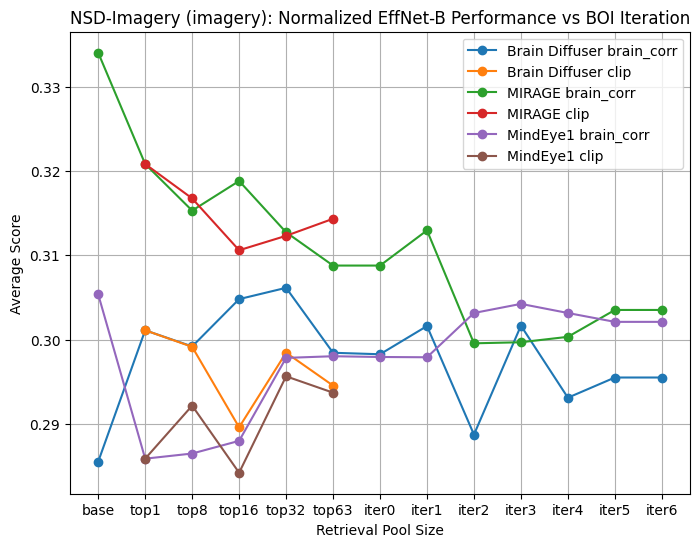

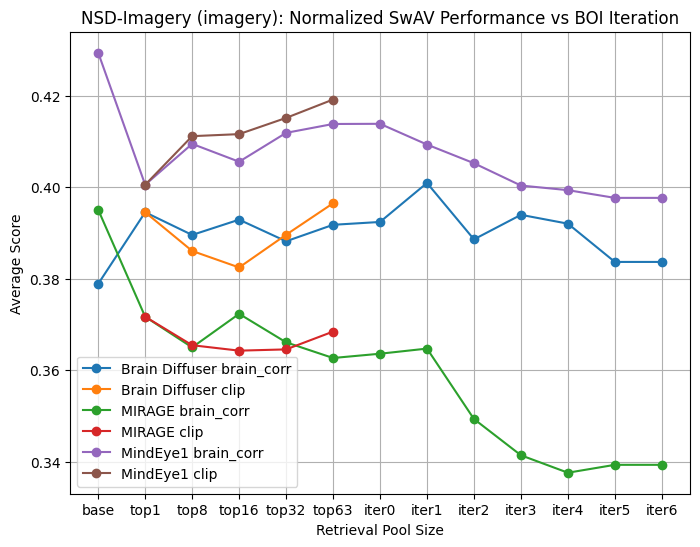

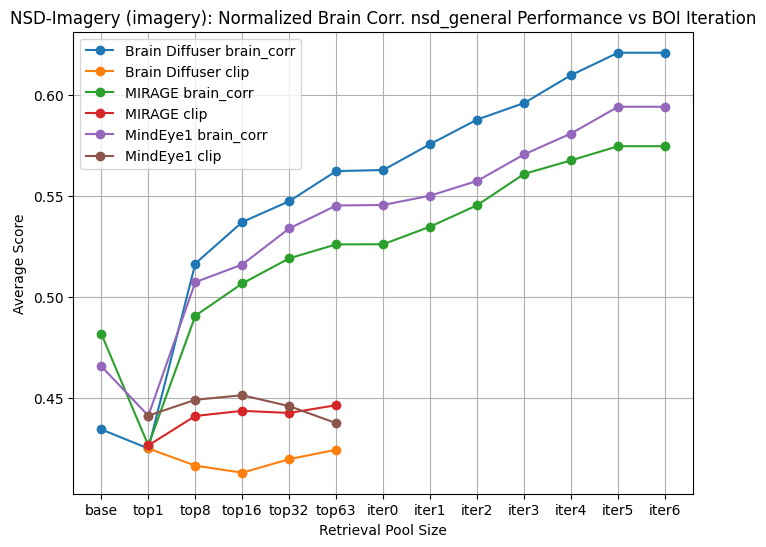

In [46]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/figures/"
criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    "Brain Corr. nsd_general",
    # "Brain Corr. EVC",
    # "Brain Corr. higher_vis",
]
for mode in ['vision', 'imagery']:
    output_file = f"NSD-Imagery ({mode}): Normalized Metric Performance (no BC) vs Retrieval Size"
    all_metrics = df[df["mode"] == mode].copy()
    scaler = MinMaxScaler()
    all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
    all_metrics['iteration'] = pd.Categorical(all_metrics['iteration'], categories=iterations, ordered=True)
    method_mode_scores = all_metrics.groupby(['iteration', 'method', 'metric'])[criteria].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    method_mode_scores = method_mode_scores.reset_index()

    plt.figure(figsize=(8, 6))
    for method in method_mode_scores['method'].unique():
        for metric in method_mode_scores['metric'].unique():
            method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
            plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=f"{method} {metric}")
    plt.xlabel('Retrieval Pool Size')
    plt.ylabel('Average Score')
    plt.title(output_file)
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(output_path, f"{output_file}.png"))
    plt.show()

    for criterion in criteria:
        single_criterion = [criterion]
        output_file = f"NSD-Imagery ({mode}): Normalized {criterion} Performance vs BOI Iteration"
        all_metrics = df.copy()
        scaler = MinMaxScaler()
        all_metrics[single_criterion] = scaler.fit_transform(all_metrics[single_criterion])
        all_metrics['iteration'] = pd.Categorical(all_metrics['iteration'], categories=iterations, ordered=True)
        method_mode_scores = all_metrics.groupby(['iteration', 'method', 'metric'])[single_criterion].mean()
        method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
        method_mode_scores = method_mode_scores.reset_index()
        
        plt.figure(figsize=(8, 6))
        for method in method_mode_scores['method'].unique():
            for metric in method_mode_scores['metric'].unique():
                method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
                plt.plot(method_data['iteration'], method_data['average_score'], marker='o', label=f"{method} {metric}")
        plt.xlabel('Retrieval Pool Size')
        plt.ylabel('Average Score')
        plt.title(output_file)
        plt.legend()
        plt.grid(True)
        plt.savefig(os.path.join(output_path, f"{output_file}.png"))
        plt.show()


In [19]:
# Assemble dataframes
root = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/dataframes/"
df = pd.DataFrame()
for mode in ['imagery', 'vision']:
    for method, name in [("mindeye1", "MindEye1"), ("braindiffuser", "Brain Diffuser"), ("mirage", "MIRAGE")]:
        for metric in ['clip']:
            for subject in [5]:
                for topn in range(1, 64):
                    new_df = pd.read_csv(f"{root}/{method}_top{topn}_{metric}_subj0{subject}_all_recons_{mode}.csv", delimiter="\t")
                    new_df["topn"] = topn
                    new_df["subject"] = subject
                    new_df["method"] = name
                    new_df["metric"] = metric
                    new_df["mode"] = mode
                    df = pd.concat([df, new_df])

df['EffNet-B'] = 1 - df['EffNet-B']
df['SwAV'] = 1 - df['SwAV']
print(len(df))
df.dropna(inplace=True)
print(len(df))

4536
4536


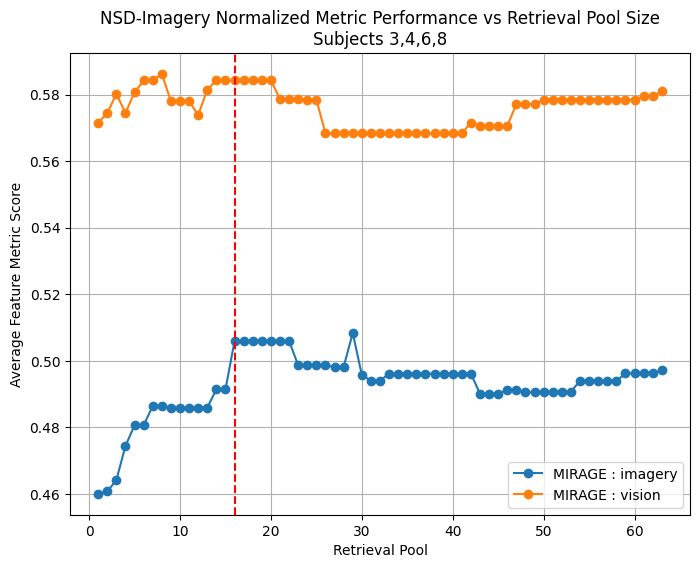

In [27]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/mental_imagery_paper_b3/figures/"
criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    "Brain Corr. nsd_general",
    "Brain Corr. EVC",
    "Brain Corr. higher_vis",
]

plt.figure(figsize=(8, 6))
output_file = f"NSD-Imagery Normalized Metric Performance vs Retrieval Pool Size\nSubjects 3,4,6,8"
all_metrics = df.copy()
scaler = MinMaxScaler()
all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
method_mode_scores = all_metrics.groupby(['topn', 'method', 'mode'])[criteria].mean()
method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
method_mode_scores = method_mode_scores.reset_index()
for mode in ['imagery', 'vision']:
    for method in ['MIRAGE']:
        method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['mode'] == mode)]
        if 16 in method_data['topn'].values and 17 in method_data['topn'].values:
            value_x17 = method_data.loc[method_data['topn'] == 17, 'average_score'].iloc[0]
            method_data.loc[method_data['topn'] == 16, 'average_score'] = value_x17
        plt.plot(method_data['topn'], method_data['average_score'], marker='o', label=f"{method} : {mode}")
plt.axvline(x=16, color='r', linestyle='--')
plt.xlabel('Retrieval Pool')
plt.ylabel('Average Feature Metric Score')
plt.title(output_file)
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_path, f"{output_file}.png"))
plt.show()

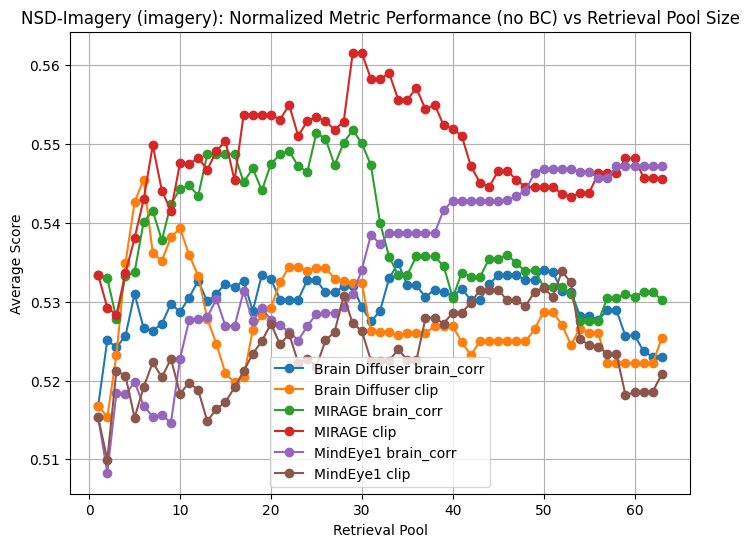

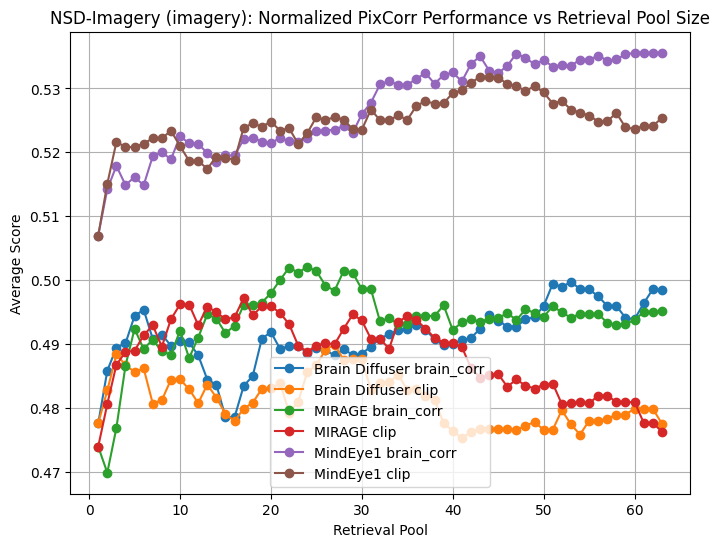

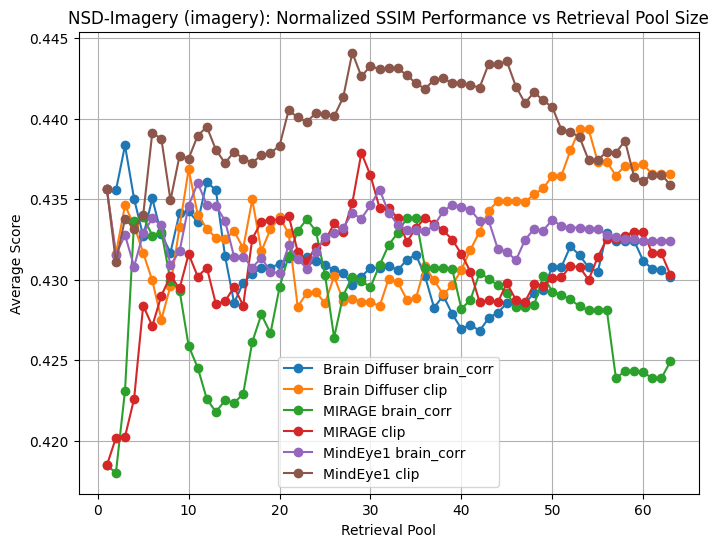

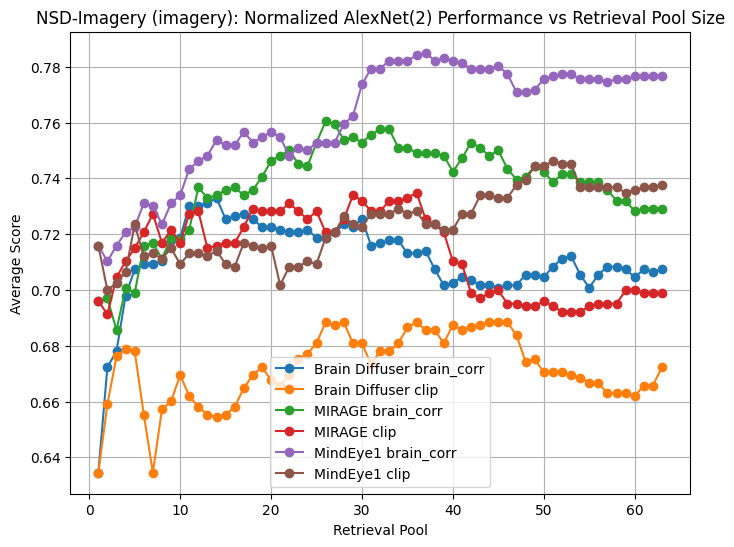

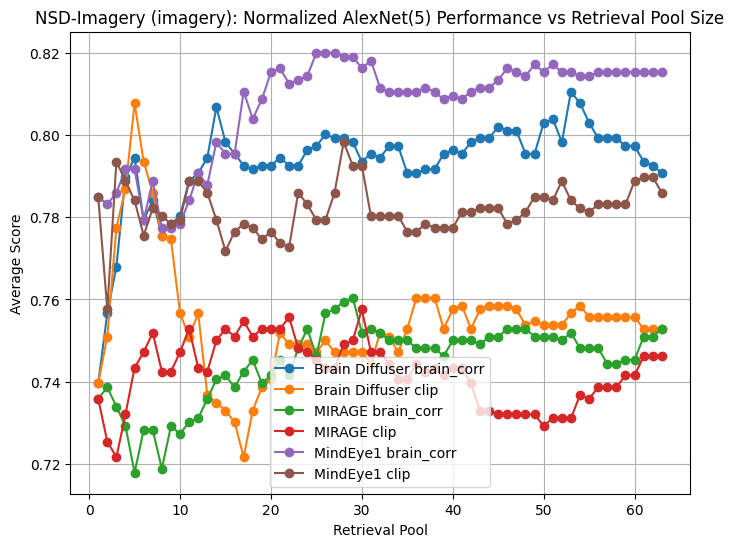

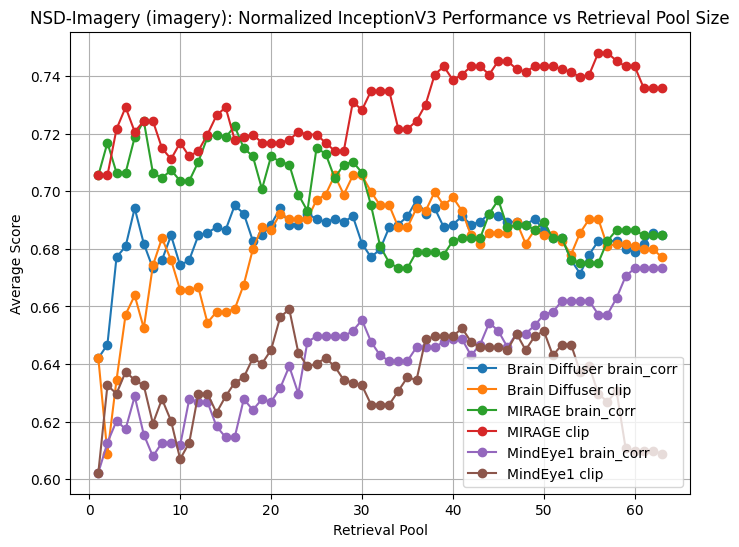

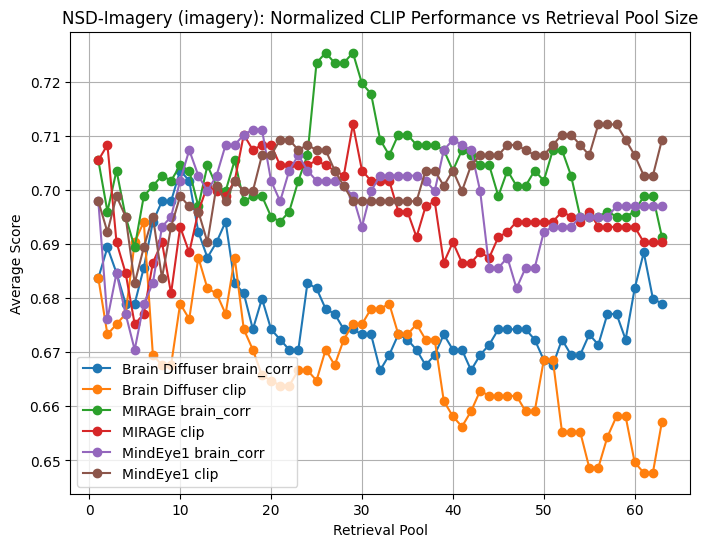

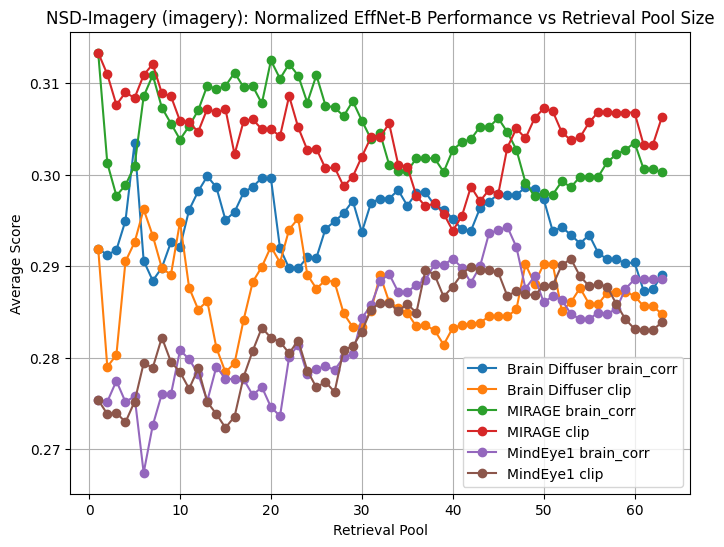

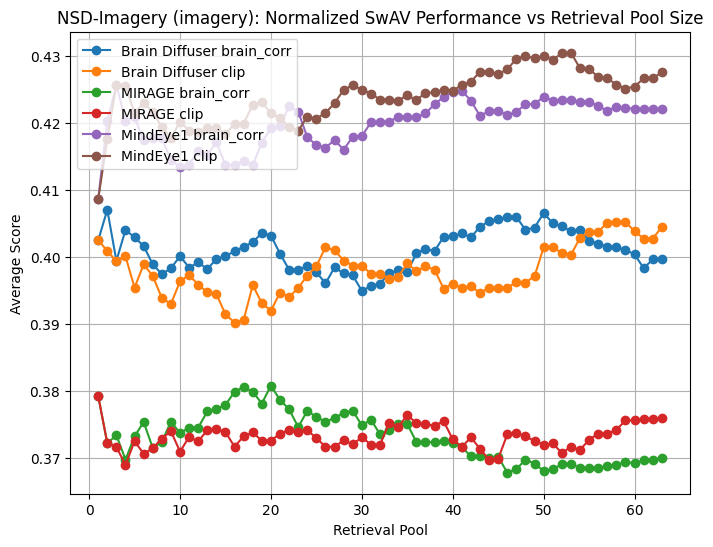

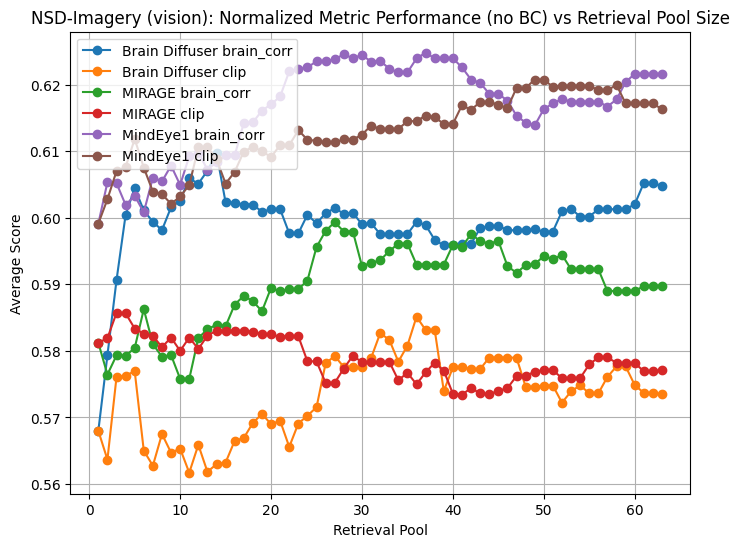

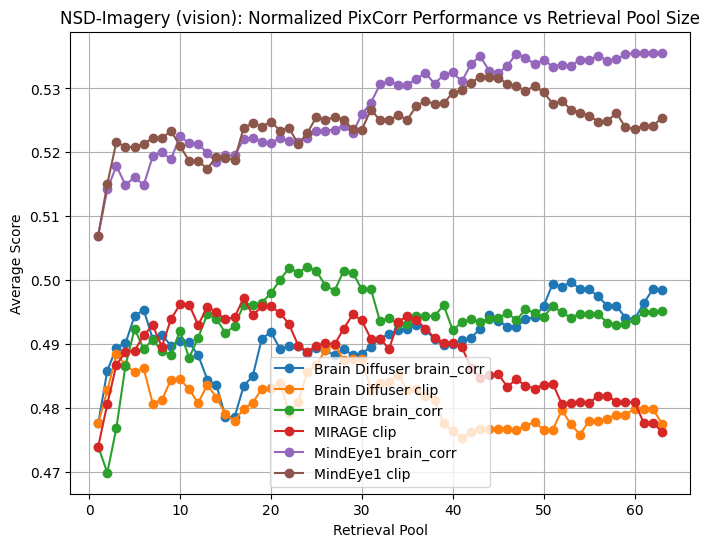

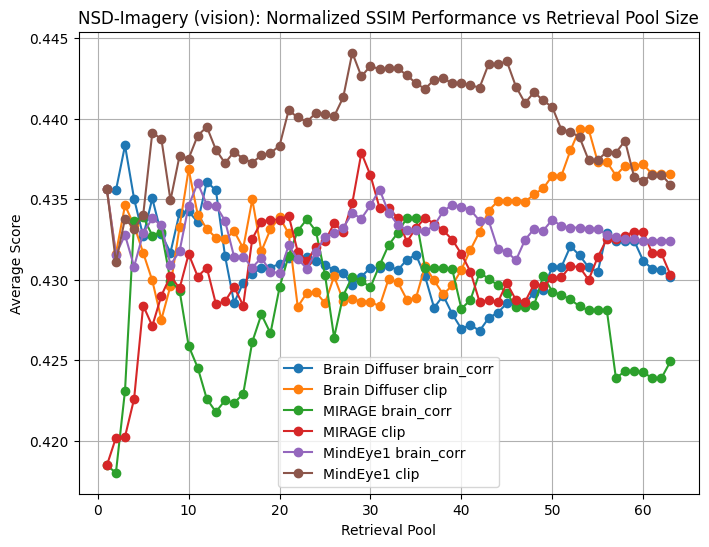

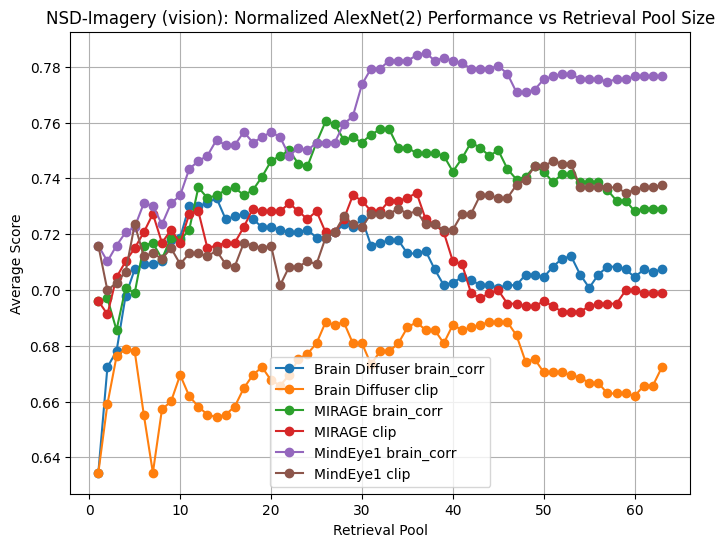

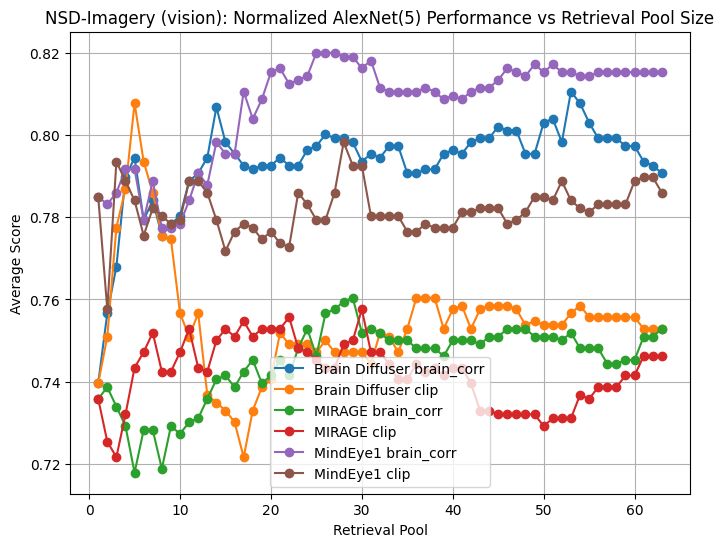

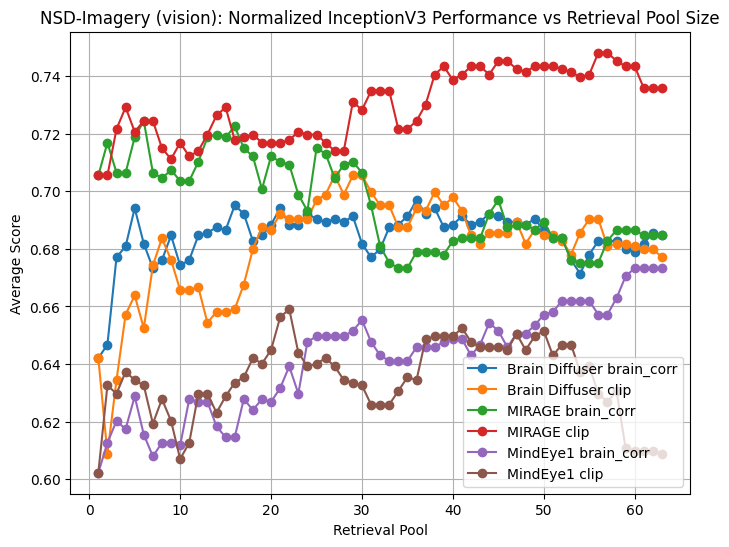

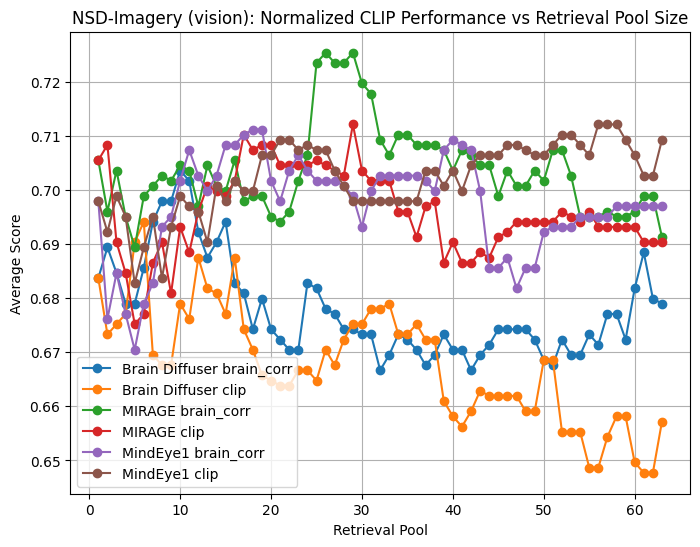

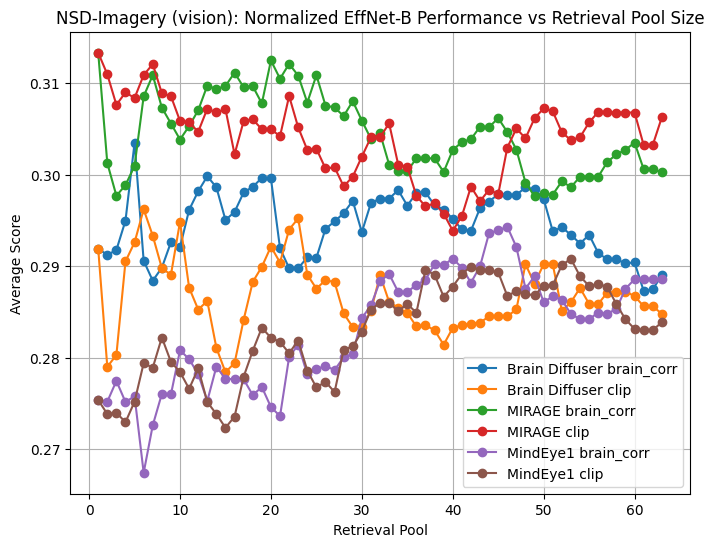

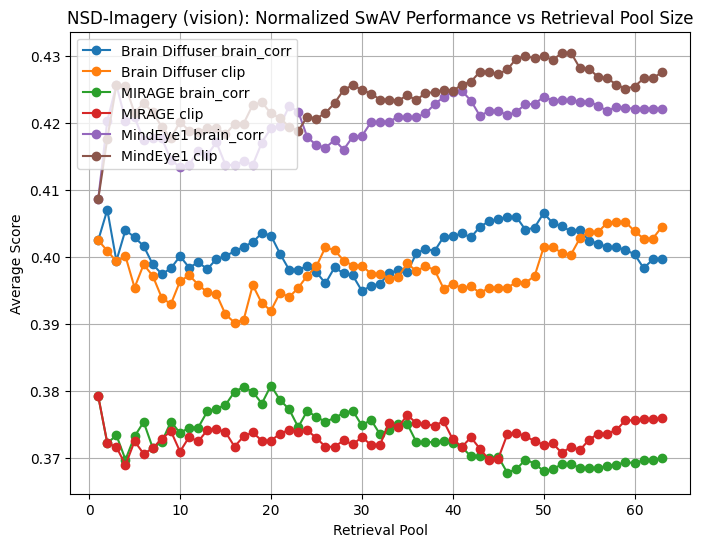

In [39]:
output_path = "/home/naxos2-raid25/kneel027/home/kneel027/Second-Sight/output/boi_paper/figures/"
criteria = [
    "PixCorr",
    "SSIM",
    "AlexNet(2)",
    "AlexNet(5)",
    "InceptionV3",
    "CLIP",
    "EffNet-B",
    "SwAV",
    # "Brain Corr. nsd_general",
    # "Brain Corr. EVC",
    # "Brain Corr. higher_vis",
]
for mode in ['imagery', 'vision']:
    output_file = f"NSD-Imagery ({mode}): Normalized Metric Performance (no BC) vs Retrieval Pool Size"
    all_metrics = df[df["mode"] == mode].copy()
    scaler = MinMaxScaler()
    all_metrics[criteria] = scaler.fit_transform(all_metrics[criteria])
    method_mode_scores = all_metrics.groupby(['topn', 'method', 'metric'])[criteria].mean()
    method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
    method_mode_scores = method_mode_scores.reset_index()

    plt.figure(figsize=(8, 6))
    for method in method_mode_scores['method'].unique():
        for metric in method_mode_scores['metric'].unique():
            method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
            plt.plot(method_data['topn'], method_data['average_score'], marker='o', label=f"{method} {metric}")
    plt.xlabel('Retrieval Pool')
    plt.ylabel('Average Score')
    plt.title(output_file)
    plt.legend()
    plt.grid(True)
    plt.savefig(os.path.join(output_path, f"{output_file}.png"))
    plt.show()

    for criterion in criteria:
        single_criterion = [criterion]
        output_file = f"NSD-Imagery ({mode}): Normalized {criterion} Performance vs Retrieval Pool Size"
        all_metrics = df.copy()
        scaler = MinMaxScaler()
        all_metrics[single_criterion] = scaler.fit_transform(all_metrics[single_criterion])
        method_mode_scores = all_metrics.groupby(['topn', 'method', 'metric'])[single_criterion].mean()
        method_mode_scores['average_score'] = method_mode_scores.mean(axis=1)
        method_mode_scores = method_mode_scores.reset_index()
        
        plt.figure(figsize=(8, 6))
        for method in method_mode_scores['method'].unique():
            for metric in method_mode_scores['metric'].unique():
                method_data = method_mode_scores[(method_mode_scores['method'] == method) & (method_mode_scores['metric'] == metric)]
                plt.plot(method_data['topn'], method_data['average_score'], marker='o', label=f"{method} {metric}")
        plt.xlabel('Retrieval Pool')
        plt.ylabel('Average Score')
        plt.title(output_file)
        plt.legend()
        plt.grid(True)
        plt.savefig(os.path.join(output_path, f"{output_file}.png"))
        plt.show()
